In [1]:
# Required first cell: third-party dependencies (no upgrade of compatible versions).
!pip install -q "numpy>=1.26" "pandas>=2.2" "scipy>=1.13" "matplotlib>=3.8" "ipython>=8"

# 0. Introduction and Setup
## 0.1 Assignment objectives
# Developer compensation: work arrangements and education
**MIE1624, Assignment 1, Fall 2026 | Questions 1–3**  
**Student:** `Peinado` · **Student number:** `1012953314`

This notebook investigates job satisfaction and compensation, compares remote and hybrid
workers globally, and compares three education groups in the United States and Canada.
It combines reproducible calculations with explanations of statistical uncertainty.
All salaries are annual compensation in **USD**; all Q2 differences are **Remote − Hybrid**.

**Reading guide:** Each method introduces its concept and formula, then implements it,
displays actual results, and interprets those results immediately below. Q2 receives most
attention. The final section collects findings for a future report.

**Method references (documentation only; no external data are loaded):**
[Student/Welch t-tests](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html),
[Mood's median test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.median_test.html),
[one-way ANOVA](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html),
[Levene's test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.levene.html), and
[Shalizi, *The Bootstrap*, §5.2.4](https://stat.cmu.edu/~cshalizi/uADA/12/lectures/ch05.pdf).

## 0.2 Required libraries and reproducibility
NumPy provides independent, named random streams from seed **16242026**. Every bootstrap
analysis uses **10,000 replications** and resamples each group to its original size.
Replication is computational repetition, not an increase in the number of survey respondents.
Library versions are printed so the execution environment can be recorded.

In [2]:
import hashlib
import platform
import textwrap
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

SEED = 16242026
# Bootstrap replications
B = 10_000
ALPHA = 0.05
SALARY = 'ConvertedCompYearly'
COLORS = ['#176B87', '#D97732', '#7354A3']
streams = dict(zip(
    ['q2_remote', 'q2_hybrid', 'median_remote', 'median_hybrid',
     'bachelor', 'master', 'professional'],
    [np.random.default_rng(s) for s in np.random.SeedSequence(SEED).spawn(7)]
))
plt.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 200, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.labelcolor': '#243746',
    'axes.titlesize': 12, 'figure.facecolor': 'white',
})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.float_format', lambda x: f'{x:.4e}' if 0 < abs(x) < .001 else f'{x:,.3f}')
primary_figures = []
def show_figure(fig, figure_id):
    primary_figures.append(figure_id)
    plt.show()
    plt.close(fig)

def narrative(text):
    display(Markdown(text))

def money(x):
    # Escape currency signs so Markdown does not interpret them as inline mathematics.
    return ('-' if x < 0 else '') + r'\$' + f'{abs(x):,.2f}'

def ptext(p):
    return f'{p:.4g}' if p > 0 else '< floating-point resolution (not exactly zero)'

def decision(p):
    return 'Reject H0' if p < ALPHA else 'Fail to reject H0'

def summary_table(groups):
    rows = {}
    for name, x in groups.items():
        q1, q3 = np.quantile(x, [0.25, 0.75])
        rows[name] = {'n': len(x), 'Mean': np.mean(x), 'Median': np.median(x),
                      'SD': np.std(x, ddof=1), 'Variance (USD²)': np.var(x, ddof=1),
                      'Minimum': np.min(x), 'Q1': q1, 'Q3': q3,
                      'IQR': q3-q1, 'Maximum': np.max(x)}
    return pd.DataFrame(rows).T

def outlier_table(groups):
    rows = {}
    for name, x in groups.items():
        q1, q3 = np.quantile(x, [0.25, 0.75])
        lo, hi = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
        flag = (x < lo) | (x > hi)
        rows[name] = {'Lower fence': lo, 'Upper fence': hi,
                      'Flagged n': flag.sum(), 'Flagged %': 100*flag.mean(),
                      'Skewness': stats.skew(x, bias=False),
                      'Largest share of sum %': 100*x.max()/x.sum()}
    return pd.DataFrame(rows).T

def within_iqr(x):
    q1, q3 = np.quantile(x, [0.25, 0.75])
    return x[(x >= q1-1.5*(q3-q1)) & (x <= q3+1.5*(q3-q1))]

def bootstrap_summary(x, rng, repetitions=B, include_median=False):
    """Independent n-out-of-n bootstrap; at most ~250,000 sampled values per batch."""
    x = np.asarray(x, dtype=float)
    n = len(x)
    assert n > 1 and np.isfinite(x).all()
    batch_size = max(1, min(64, 250_000 // n))
    result = {'mean': np.empty(repetitions), 'variance': np.empty(repetitions),
              'sample_size': n, 'replications': repetitions}
    if include_median:
        result['median'] = np.empty(repetitions)
    for start in range(0, repetitions, batch_size):
        stop = min(start + batch_size, repetitions)
        draws = rng.choice(x, size=(stop-start, n), replace=True)
        result['mean'][start:stop] = draws.mean(axis=1)
        result['variance'][start:stop] = draws.var(axis=1, ddof=1)
        if include_median:
            result['median'][start:stop] = np.median(draws, axis=1)
    return result

def standardize(x):
    return (x - np.mean(x)) / np.std(x, ddof=1)

def empirical_test(null_statistics, observed, two_sided=False):
    null_statistics = np.asarray(null_statistics)
    assert len(null_statistics) == B and np.isfinite(null_statistics).all()
    extreme = (np.abs(null_statistics) >= abs(observed)) if two_sided else (null_statistics >= observed)
    hits = int(extreme.sum())
    p = (hits + 1) / (B + 1)
    # Exact binomial interval describes simulation uncertainty, not uncertainty from sampling people.
    mc = stats.binomtest(hits, B).proportion_ci(confidence_level=.95, method='exact')
    return {'p': p, 'exceedances': hits, 'B': B,
            'MC tail lower': mc.low, 'MC tail upper': mc.high}

versions = pd.Series({'Python': platform.python_version(), 'NumPy': np.__version__,
                      'pandas': pd.__version__, 'SciPy': scipy.__version__,
                      'Matplotlib': matplotlib.__version__, 'Seed': SEED, 'Replications': B})
display(versions.to_frame('Execution setting'))

,Execution setting
Python,3.10.19
NumPy,2.2.5
pandas,2.3.1
SciPy,1.15.3
Matplotlib,3.10.0
Seed,16242026
Replications,10000


## 0.3 Dataset loading and validation
The provided cleaned survey is the only data source. We inspect its real schema before
filtering. A SHA-256 fingerprint checks that the source file remains byte-for-byte unchanged.
Validation failures stop execution instead of silently changing the population being studied.

### Study Population and Sample Selection Criteria
The intended study concerns workforce participation. Two researcher-defined sample selection
criteria operationalize the analytical scope and engineering judgment: exclude respondents
explicitly classified as retired, and exclude recorded ages greater than 80 years. Age 80
remains eligible. The upper age limit defines the research population; it does not establish
that older respondents are erroneous or statistical outliers. These eligibility decisions
precede all descriptive and inferential analyses and are distinct from satisfaction-scale
cleaning and the separate salary-IQR sensitivity analyses.

Inspection of the supplied CSV identifies four `Employment` categories: `Employed`,
`Independent contractor, freelancer, or self-employed`, `Student`, and `Not employed`.
There is no retired category in that field. Two rows instead have `DevType = Retired`,
although both also have `Employment = Employed`. We prioritize the explicit retired
classification for exclusion, without guessing which conflicting field is correct.
`EmploymentAddl` contains semicolon-delimited activities, including `Transitioning to
retirement (gradually reducing work hours)`; transition is not completed retirement and
is not itself grounds for exclusion. Exact, case-normalized retired tokens are checked
across all three fields, rather than matching the substring "retir".

Excluding retirement does **not** establish that everyone remaining is employed. The
employment categories and supplementary paid-work responses support a self-reported
employment indicator, but students and those marked not employed remain under these two
specified criteria. We report these categories and the indicator as an audit, without imposing
an additional employed-only filter. Findings therefore concern the selected salary-reporting
survey respondents, not a verified population of actively employed workers. Employment timing,
conflicting classifications, and the original cleaning history cannot be independently verified.

Missing ages are retained for analyses that do not require age because they do not establish
an age above 80; they are excluded from the age plot. Thus the age ceiling is verified only
for respondents with recorded ages. The sample-flow table reports each criterion separately,
their overlap, sequential removals, and the final sample without double-counting.


In [3]:
from pathlib import Path

data_candidates = [
    Path("data/raw_data/clean_stackoverflow_data.csv"),
    Path("../data/raw_data/clean_stackoverflow_data.csv"),
    Path("clean_stackoverflow_data.csv"),
]
data_path = next((candidate for candidate in data_candidates if candidate.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        "CSV not found. Start the kernel in the repository root or notebooks/ with "
        "the dataset in data/raw_data/, or upload the CSV to the Colab working directory."
    )

with open(data_path, 'rb') as source:
    source_hash_before = hashlib.sha256(source.read()).hexdigest()
source_survey = pd.read_csv(data_path)
survey = source_survey.copy()
original_frame_hash = pd.util.hash_pandas_object(survey, index=True).to_numpy().copy()
SAT = survey.columns[-1]
required = ['Employment', 'EmploymentAddl', 'Age', 'EdLevel', 'DevType', 'RemoteWork', 'Country', SALARY, SAT]
assert SAT == 'JobSat', f'Review unexpected last column: {SAT}'
assert set(required).issubset(survey.columns)
assert pd.api.types.is_numeric_dtype(survey[SALARY])
assert pd.api.types.is_numeric_dtype(survey['Age'])
assert pd.api.types.is_numeric_dtype(survey[SAT])
assert np.isfinite(survey[SALARY]).all() and survey[SALARY].gt(0).all()
assert {'Remote', 'Hybrid'}.issubset(set(survey.RemoteWork.dropna()))
education_labels = ["Bachelor's degree", "Master's degree", 'Professional degree']
north_america = ['United States of America', 'Canada']
assert set(education_labels).issubset(set(survey.EdLevel.dropna()))
assert set(north_america).issubset(set(survey.Country.dropna()))
# Eligibility selection precedes every descriptive statistic, plot and test.
def has_exact_token(series, label):
    return series.fillna('').astype(str).str.split(';').map(
        lambda tokens: label.casefold() in {t.strip().casefold() for t in tokens})

retired_by_field = pd.DataFrame({column: has_exact_token(source_survey[column], 'Retired')
                               for column in ['Employment', 'EmploymentAddl', 'DevType']})
retired_mask = retired_by_field.any(axis=1)
over_80_mask = source_survey.Age.gt(80)
selection_mask = ~(retired_mask | over_80_mask)
survey = source_survey.loc[selection_mask].copy()
selected_frame_hash = pd.util.hash_pandas_object(survey, index=True).to_numpy().copy()
original_n = len(source_survey)
retired_n = int(retired_mask.sum())
over_80_n = int(over_80_mask.sum())
overlap_n = int((retired_mask & over_80_mask).sum())
age_excluded_after_retirement = int((~retired_mask & over_80_mask).sum())
selection_flow = pd.DataFrame({
    'Stage': ['Original supplied sample', 'Exclude retired', 'Exclude age >80 after retirement',
              'Final analysis sample'],
    'Excluded at stage': [0, retired_n, age_excluded_after_retirement, 0],
    'Remaining': [original_n, original_n-retired_n, len(survey), len(survey)]
})
display(retired_by_field.sum().rename('Explicit retired classifications').to_frame())
display(source_survey.Employment.value_counts(dropna=False).rename('Original employment categories').to_frame())
display(source_survey.EmploymentAddl.dropna().str.split(';').explode().str.strip()
        .value_counts().rename('Supplementary activity tokens (multiple per respondent)').to_frame())
display(selection_flow)
employment_audit = survey.Employment.value_counts(dropna=False).rename('Selected respondents').to_frame()
display(employment_audit)
reported_employment = survey.Employment.isin(['Employed', 'Independent contractor, freelancer, or self-employed'])
reported_paid_activity = survey.EmploymentAddl.fillna('').str.split(';').map(
    lambda tokens: any(t.strip().startswith('Engaged in paid work (') for t in tokens))
employment_indicator_n = int((reported_employment | reported_paid_activity).sum())
narrative(f'**Sample selection.** Original n={original_n:,}; retired exclusions={retired_n:,}; '
          f'age >80 exclusions in the original sample={over_80_n:,}; overlap={overlap_n:,}; '
          f'additional age exclusions after retirement={age_excluded_after_retirement:,}; '
          f'final n={len(survey):,}. The selected sample retains '
          f'{int(survey.Age.eq(80).sum()):,} respondents aged exactly 80 and '
          f'{int(survey.Age.isna().sum()):,} with missing age. '
          f'{employment_indicator_n:,} report employment/self-employment or supplementary paid work; '
          f'{len(survey)-employment_indicator_n:,} lack that affirmative indicator. '
          'This indicator is descriptive, not an additional eligibility restriction or external verification.')

schema = pd.DataFrame({'Type': survey[required].dtypes.astype(str),
                       'Missing n': survey[required].isna().sum(),
                       'Missing %': 100*survey[required].isna().mean(),
                       'Distinct nonmissing': survey[required].nunique()})
display(schema)
for column in ['RemoteWork', 'EdLevel']:
    display(survey[column].value_counts(dropna=False).rename('Respondents').to_frame())
display(survey['Country'].value_counts().head(10).rename('Respondents (top 10 countries)').to_frame())
display(survey[SAT].value_counts(dropna=False).sort_index().rename('Satisfaction count').to_frame())
narrative(f'**Results.** The selected analysis sample has **{len(survey):,} rows and {survey.shape[1]} columns**; '
          f'its final column is `{SAT}` and annual salary is `{SALARY}`. '
          f'Age is numeric, spanning {survey.Age.min():g}–{survey.Age.max():g}; '
          f'{survey.Age.isna().sum()} ages are missing. All salary entries are finite and positive.')

,Explicit retired classifications
Employment,0
EmploymentAddl,0
DevType,2


,Original employment categories
Employment,
Employed,18903
"Independent contractor, freelancer, or self-employed",1124
Student,321
Not employed,59


,Supplementary activity tokens (multiple per respondent)
EmploymentAddl,
None of the above,8739
"Caring for dependents (children, elderly, etc.)",4400
Engaged in paid work (20-29 hours per week),3088
Volunteering (regularly),2489
Engaged in paid work (less than 10 hours per week),1560
Attending school (part-time),1034
Engaged in paid work (10-19 hours per week),794
Attending school (full-time),567
Transitioning to retirement (gradually reducing work hours),245


,Stage,Excluded at stage,Remaining
0,Original supplied sample,0,20407
1,Exclude retired,2,20405
2,Exclude age >80 after retirement,93,20312
3,Final analysis sample,0,20312


,Selected respondents
Employment,
Employed,18827
"Independent contractor, freelancer, or self-employed",1106
Student,321
Not employed,58


...

,Respondents
RemoteWork,
Hybrid,7776
Remote,6888
In-person,2985
Your choice (very flexible),2663


,Respondents
EdLevel,
Bachelor's degree,9047
Master's degree,5917
Some college/university study without earning a degree,2335
Professional degree,1173
Secondary school,919
Associate degree,674
Other,164
Primary/elementary school,83


,Respondents (top 10 countries)
Country,
United States of America,4630
Germany,1906
Great Britain,1316
India,938
France,862
Canada,783
Ukraine,560
Netherlands,535
Brazil,522


,Satisfaction count
JobSat,
0.000,91
1.000,105
2.000,279
3.000,552
4.000,520
5.000,1097
6.000,2133
7.000,3683
8.000,4546


**Results.** The selected analysis sample has **20,312 rows and 168 columns**; its final column is `JobSat` and annual salary is `ConvertedCompYearly`. Age is numeric, spanning 1–80; 10 ages are missing. All salary entries are finite and positive.

## 0.4 Dataset characteristics and preparation
**Concept.** A mean summarizes location but is sensitive to extreme observations; a median
describes the middle observation. Standard deviation summarizes dispersion of individual
values, whereas sample variance measures that dispersion in squared units. Missingness can
differ by question, so a global complete-case filter would discard usable salaries unnecessarily.
Category counts indicate how much support each group average has.

**Preparation decisions.** Keep the source DataFrame unchanged; apply the population criteria above, then select only the variables
required for each analysis. For satisfaction, use the explicit working validity rule **0–10**:
nearly all nonmissing entries lie on this integer scale, while 60 is an apparent coding anomaly.
No accompanying cleaned-data codebook establishes its intended replacement, so exclude it
only from the satisfaction calculation, without recoding it. Show its effect on the affected
job-title mean. Treat the rating numerically for the requested average, acknowledging its ordinal nature.
For age, retain every eligible nonmissing numeric value in the scatterplot and visibly flag values
outside **15–100** as a diagnostic screen, not a verified eligibility rule.
The retirement and age-ceiling criteria apply to every analysis, including Q2 and Q3.
Other age diagnostics and satisfaction validity rules do not trigger additional salary exclusions.

In [4]:
display(survey[[SALARY, 'Age', SAT]].describe(percentiles=[.25, .5, .75, .95, .99]).T)
satisfaction_invalid = survey[SAT].notna() & ~survey[SAT].between(0, 10)
age_suspect = survey['Age'].notna() & ~survey['Age'].between(15, 100)
display(pd.DataFrame({
    'Issue': ['Missing satisfaction', 'Satisfaction outside 0–10', 'Missing age',
              'Age outside diagnostic range 15–100', 'Exact duplicate rows'],
    'Count': [survey[SAT].isna().sum(), satisfaction_invalid.sum(), survey.Age.isna().sum(),
              age_suspect.sum(), survey.duplicated().sum()],
    'Action': ['Exclude only from Q1.1', 'Exclude only from Q1.1; no guessed replacement',
               'Exclude only from Q1.3', 'Retain and flag in Q1.3',
               'Inspect count; no automatic deletion without respondent IDs']
}))
# No external files, mapping tables, or global dropna are used.
satisfaction_data = survey.loc[survey[SAT].between(0, 10) & survey.DevType.notna(), ['DevType', SAT]].copy()
title_salary_data = survey.loc[survey.DevType.notna(), ['DevType', SALARY]].copy()
age_salary_data = survey.loc[survey.Age.notna(), ['Age', SALARY]].copy()
narrative(f'**Interpretation.** The overall mean salary is {money(survey[SALARY].mean())}, '
          f'versus a median of {money(survey[SALARY].median())}; the maximum is '
          f'{money(survey[SALARY].max())}. The right tail can dominate mean-based conclusions. '
          f'The three EDA samples contain {len(satisfaction_data):,}, {len(title_salary_data):,}, '
          f'and {len(age_salary_data):,} rows respectively. '
          'These are different valid subsets, not inconsistent filtering.')

,count,mean,std,min,25%,50%,75%,95%,99%,max
ConvertedCompYearly,"20,312.000","101,926.207","340,255.532",102.000,"42,125.000","77,730.000","123,518.000","235,000.000","440,761.840","33,552,715.000"
Age,"20,302.000",36.543,10.542,1.000,28.250,35.000,43.000,56.000,63.000,80.000
JobSat,"16,884.000",7.188,1.968,0.000,6.000,7.000,8.000,10.000,10.000,60.000


,Issue,Count,Action
0,Missing satisfaction,3428,Exclude only from Q1.1
1,Satisfaction outside 0–10,1,Exclude only from Q1.1; no guessed replacement
2,Missing age,10,Exclude only from Q1.3
3,Age outside diagnostic range 15–100,3,Retain and flag in Q1.3
4,Exact duplicate rows,8,Inspect count; no automatic deletion without respondent IDs


**Interpretation.** The overall mean salary is \$101,926.21, versus a median of \$77,730.00; the maximum is \$33,552,715.00. The right tail can dominate mean-based conclusions. The three EDA samples contain 16,883, 20,312, and 20,302 rows respectively. These are different valid subsets, not inconsistent filtering.

# 1. Question 1 — Exploratory Data Analysis
## 1.1 Average Job Satisfaction by Job Title
**Concept and formula.** The group mean is $\bar{s}_j=(1/n_j)\sum_{i=1}^{n_j}s_{ij}$,
where $s_{ij}$ is a valid satisfaction rating and $n_j$ is the valid count for job title $j$.
It answers which titles report higher average ratings in this sample. Small groups have
unstable averages; no significance claim follows from ranking their bars. `DevType` is used
as supplied, with one category per row; no multi-response expansion is imposed.

,Mean including anomalous rating,Mean restricted to 0–10
DevType,,
Student,7.949,7.052


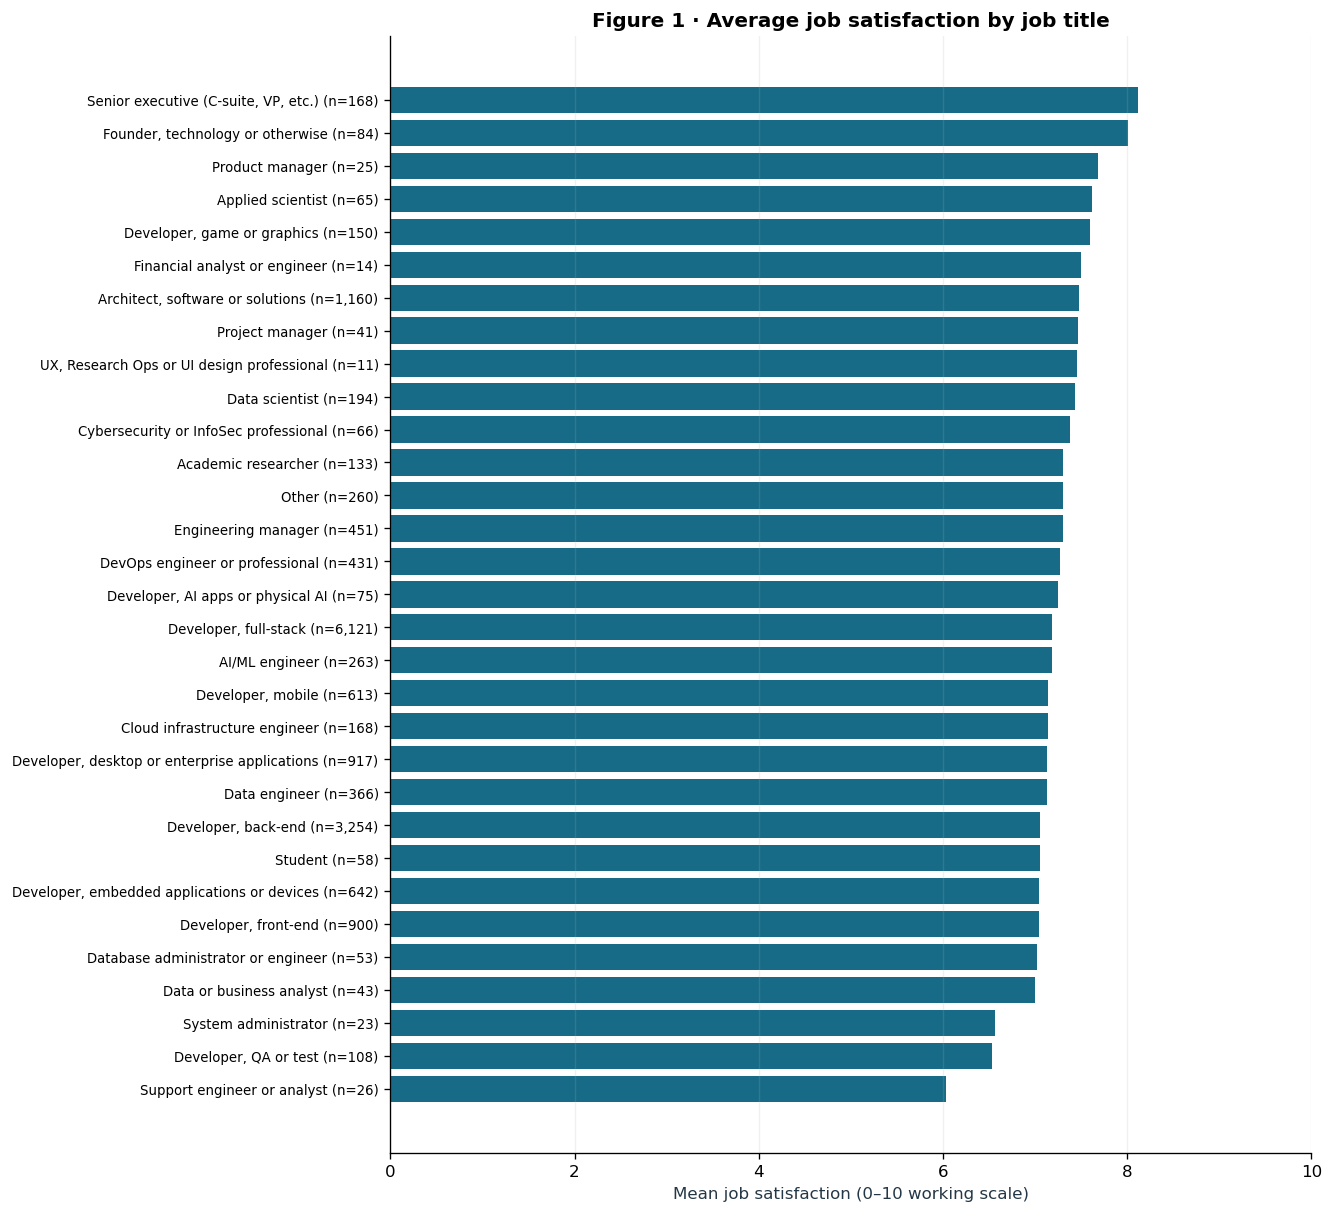

**Diagnostic sentence:** Senior executive (C-suite, VP, etc.) has the highest average valid rating (8.12/10, n=168), but the UX, Research Ops or UI design professional category’s valid sample size of 11 makes its ranking unstable.

**Methodological note:** Counts in labels are nonmissing ratings within 0–10; the sensitivity table documents the excluded rating of 60, and ordinal-scale averaging does not establish equal psychological distances between adjacent ratings.

In [5]:
satisfaction_by_title = satisfaction_data.groupby('DevType')[SAT].agg(n='count', mean='mean').sort_values('mean')
affected_titles = survey.loc[satisfaction_invalid, 'DevType'].unique()
sat_sensitivity = pd.DataFrame({
    'Mean including anomalous rating': survey.groupby('DevType')[SAT].mean(),
    'Mean restricted to 0–10': satisfaction_by_title['mean']
}).loc[affected_titles]
display(sat_sensitivity)
fig, ax = plt.subplots(figsize=(11, 10), layout='constrained')
labels = [f'{title} (n={int(row.n):,})' for title, row in satisfaction_by_title.iterrows()]
ax.barh(labels, satisfaction_by_title['mean'], color=COLORS[0])
ax.set(xlim=(0, 10), xlabel='Mean job satisfaction (0–10 working scale)',
       title='Figure 1 · Average job satisfaction by job title')
ax.tick_params(axis='y', labelsize=8)
ax.grid(axis='x', alpha=.18)
show_figure(fig, 'Figure 1')
highest = satisfaction_by_title.iloc[-1]
smallest = satisfaction_by_title['n'].idxmin()
q1_diagnostic_1 = (f'{satisfaction_by_title.index[-1]} has the highest average valid rating '
                   f'({highest["mean"]:.2f}/10, n={int(highest.n):,}), but the '
                   f'{smallest} category’s valid sample size of {int(satisfaction_by_title.loc[smallest, "n"])} '
                   'makes its ranking unstable.')
narrative('**Diagnostic sentence:** ' + q1_diagnostic_1)
narrative('**Methodological note:** Counts in labels are nonmissing ratings within 0–10; '
          'the sensitivity table documents the excluded rating of 60, and ordinal-scale averaging '
          'does not establish equal psychological distances between adjacent ratings.')

## 1.2 Mean Salary by Job Title
**Concept.** Arithmetic means answer the requested question about average compensation.
They can be much higher than medians in a right-skewed distribution. All positive finite
salaries within the selected population are retained here, so an extreme category mean is a finding to investigate rather
than a reason to change the requested statistic. Counts and median reference markers help
distinguish broad patterns from tail sensitivity.

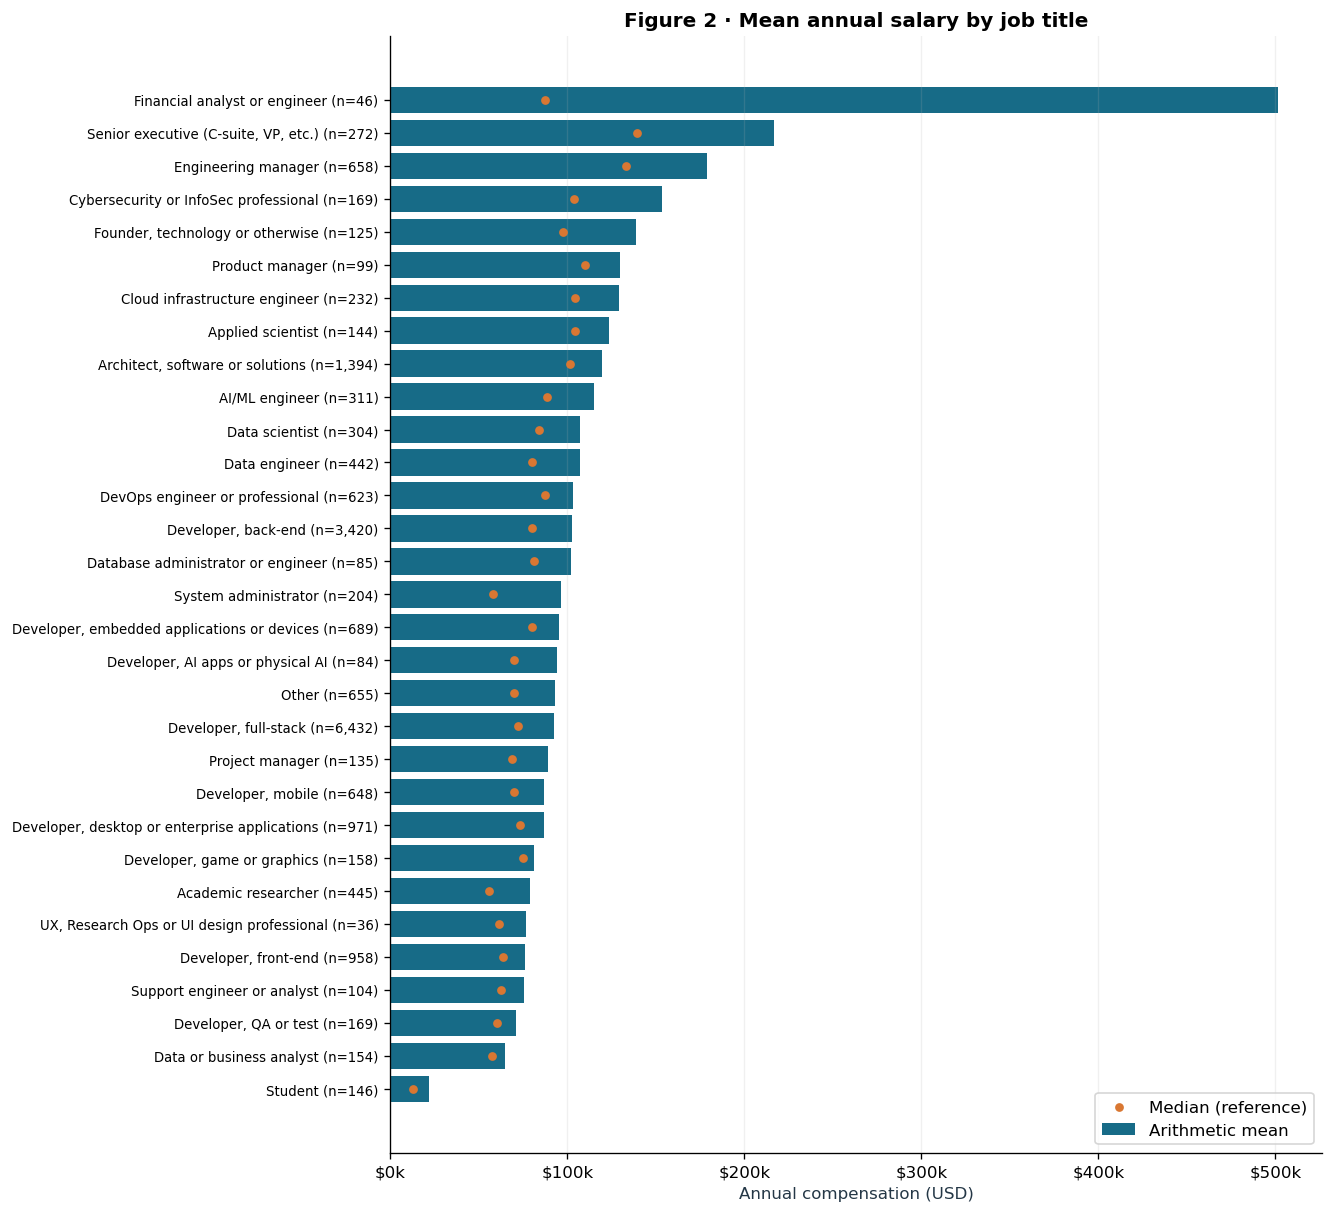

**Diagnostic sentence:** Financial analyst or engineer has the largest mean salary (\$501,248.00, n=46), compared with its median of \$87,248.50, highlighting the sensitivity of the mean to the upper tail.

In [6]:
salary_by_title = title_salary_data.groupby('DevType')[SALARY].agg(n='count', mean='mean', median='median').sort_values('mean')
fig, ax = plt.subplots(figsize=(11, 10), layout='constrained')
labels = [f'{title} (n={int(row.n):,})' for title, row in salary_by_title.iterrows()]
positions = np.arange(len(labels))
ax.barh(positions, salary_by_title['mean'], color=COLORS[0], label='Arithmetic mean')
ax.scatter(salary_by_title['median'], positions, color=COLORS[1], s=18, label='Median (reference)', zorder=3)
ax.set_yticks(positions, labels, fontsize=8)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'${x/1000:,.0f}k'))
ax.set(xlabel='Annual compensation (USD)', title='Figure 2 · Mean annual salary by job title')
ax.grid(axis='x', alpha=.18)
ax.legend(loc='lower right')
show_figure(fig, 'Figure 2')
top_title = salary_by_title.index[-1]
top = salary_by_title.loc[top_title]
q1_diagnostic_2 = (f'{top_title} has the largest mean salary ({money(top["mean"])}, '
                   f'n={int(top.n):,}), compared with its median of {money(top["median"])}, '
                   'highlighting the sensitivity of the mean to the upper tail.')
narrative('**Diagnostic sentence:** ' + q1_diagnostic_2)

## 1.3 Annual Salary vs. Age
**Concept.** A scatterplot preserves the numeric age values actually provided in this cleaned
CSV and shows individual variation. A logarithmic salary axis makes both low and exceptionally
high values visible without changing the data used for arithmetic means or tests. Age can be
associated with experience, occupation and country; a visual relationship cannot establish causation.
The preparation history of these numeric ages is unavailable, so their precision is not independently verified.

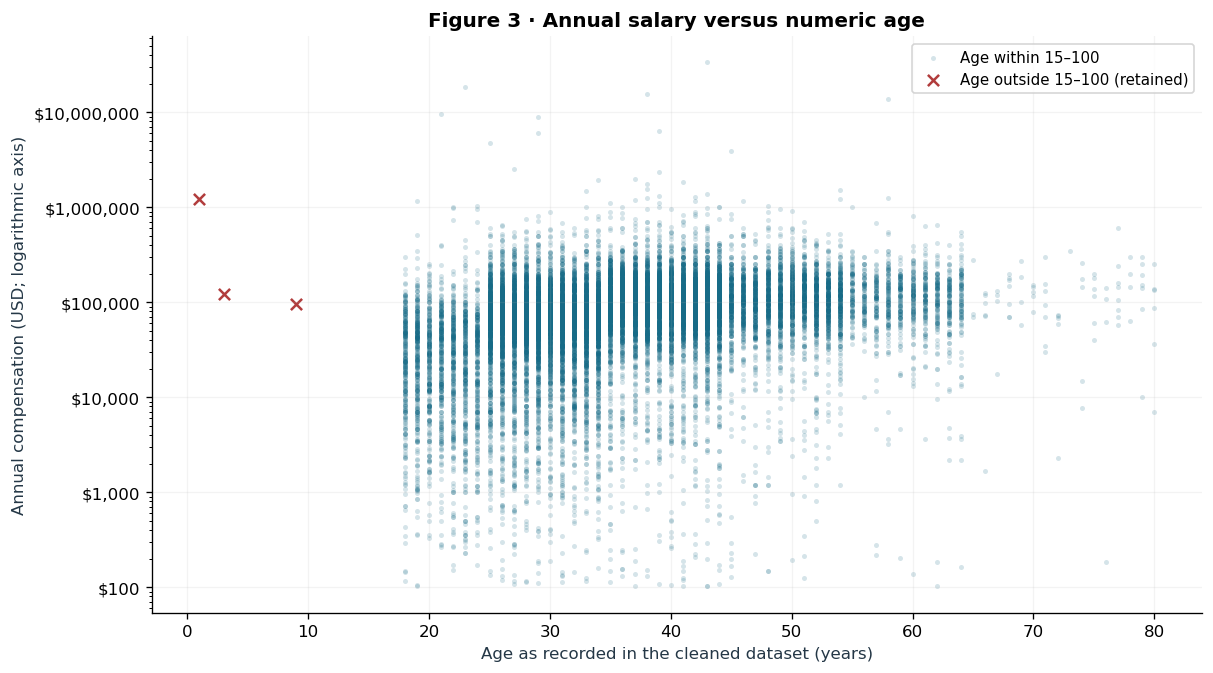

**Diagnostic sentence:** Salaries span \$102.00 to \$33,552,715.00 across recorded ages, and 3 ages outside 15–100 signal data-quality concerns that limit interpretation of the apparent age–salary pattern.

In [7]:
suspicious = ~age_salary_data.Age.between(15, 100)
fig, ax = plt.subplots(figsize=(10, 5.5), layout='constrained')
ax.scatter(age_salary_data.loc[~suspicious, 'Age'], age_salary_data.loc[~suspicious, SALARY],
           s=9, alpha=.18, color=COLORS[0], linewidths=0, rasterized=True, label='Age within 15–100')
ax.scatter(age_salary_data.loc[suspicious, 'Age'], age_salary_data.loc[suspicious, SALARY],
           s=45, marker='x', color='#B13C3C', label='Age outside 15–100 (retained)')
ax.set(yscale='log', xlabel='Age as recorded in the cleaned dataset (years)',
       ylabel='Annual compensation (USD; logarithmic axis)',
       title='Figure 3 · Annual salary versus numeric age')
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'${y:,.0f}'))
ax.grid(alpha=.15)
ax.legend(loc='upper right', fontsize=9)
show_figure(fig, 'Figure 3')
q1_diagnostic_3 = (f'Salaries span {money(age_salary_data[SALARY].min())} to '
                   f'{money(age_salary_data[SALARY].max())} across recorded ages, and '
                   f'{int(suspicious.sum())} ages outside 15–100 signal data-quality concerns '
                   'that limit interpretation of the apparent age–salary pattern.')
narrative('**Diagnostic sentence:** ' + q1_diagnostic_3)

## 1.4 EDA Summary
The three primary figures distinguish satisfaction averages, arithmetic salary averages and
individual salary variation. Unequal category counts, missing satisfaction, anomalous ages
and a long salary tail deserve more attention than a simple ranking of job titles.
The following inference uses the original salary scale and question-specific groups;
the retirement and age-ceiling criteria apply throughout Q2 and Q3, while satisfaction
cleaning and the remaining age diagnostic flags do not cause additional salary removals.

# 2. Question 2 — Salary Differences Between Hybrid and Remote Workers
## 2(a) Descriptive Statistics and Outliers
**Concept.** Compare both location and variability before testing a mean difference.
The interquartile range is $IQR=Q_3-Q_1$; Tukey's diagnostic fences are
$[Q_1-1.5IQR, Q_3+1.5IQR]$, where $Q_1,Q_3$ are sample quartiles.
A flagged observation is statistically unusual, not necessarily erroneous. Very high salaries
may reflect genuine compensation, unit errors or inaccurate reporting; the supplied data do not identify which.

**Decision.** Retain all finite positive salaries in the two exact categories for the primary analysis.
No country restriction applies. Use group-specific IQR exclusion only as a clearly labeled
sensitivity analysis: it changes the target to a truncated salary distribution and is not a
correction to the full-population mean. Never pick the version with the preferred p-value.

In [8]:
q2_data = survey.loc[survey.RemoteWork.isin(['Remote', 'Hybrid']), ['RemoteWork', SALARY]].copy()
q2_groups = {name: q2_data.loc[q2_data.RemoteWork.eq(name), SALARY].to_numpy(dtype=float)
             for name in ['Remote', 'Hybrid']}
remote, hybrid = q2_groups['Remote'], q2_groups['Hybrid']
q2_descriptives = summary_table(q2_groups)
q2_outliers = outlier_table(q2_groups)
display(q2_descriptives.T.rename_axis('Statistic (USD unless stated)'))
display(q2_outliers)
q2_trimmed = {name: within_iqr(x) for name, x in q2_groups.items()}
sensitivity_rows = []
for label, groups in [('Primary: all salaries', q2_groups), ('Sensitivity: within group IQR fences', q2_trimmed)]:
    a, b = groups['Remote'], groups['Hybrid']
    result = stats.ttest_ind(a, b, equal_var=True)
    sensitivity_rows.append({'Analysis': label, 'Remote n': len(a), 'Hybrid n': len(b),
                             'Remote mean': a.mean(), 'Hybrid mean': b.mean(),
                             'Difference (R−H)': a.mean()-b.mean(), 'Student p': ptext(result.pvalue)})
q2_sensitivity = pd.DataFrame(sensitivity_rows).set_index('Analysis')
display(q2_sensitivity)
narrative(f'**Interpretation.** Remote workers have a mean of {money(remote.mean())} and hybrid '
          f'workers {money(hybrid.mean())}; the raw difference is {money(remote.mean()-hybrid.mean())}. '
          f'The IQR-restricted difference is {money(q2_trimmed["Remote"].mean()-q2_trimmed["Hybrid"].mean())}. '
          'This sensitivity comparison quantifies how tail treatment changes the estimate; '
          'all following required calculations retain the primary samples.')

,Remote,Hybrid
Statistic (USD unless stated),,
n,"6,888.000","7,776.000"
Mean,"118,666.898","101,422.986"
Median,"90,491.000","77,730.000"
SD,"444,251.014","346,625.921"
Variance (USD²),"197,358,963,571.468","120,149,529,197.139"
Minimum,102.000,104.000
Q1,"47,566.000","47,492.250"
Q3,"150,000.000","116,015.000"
IQR,"102,434.000","68,522.750"


,Lower fence,Upper fence,Flagged n,Flagged %,Skewness,Largest share of sum %
Remote,"-106,085.000","303,651.000",204.000,2.962,63.955,4.105
Hybrid,"-55,291.875","218,799.125",400.000,5.144,41.182,2.331


,Remote n,Hybrid n,Remote mean,Hybrid mean,Difference (R−H),Student p
Analysis,,,,,,
Primary: all salaries,6888,7776,"118,666.898","101,422.986","17,243.912",0.008421
Sensitivity: within group IQR fences,6684,7376,"98,554.137","79,849.189","18,704.947",2.364e-79


**Interpretation.** Remote workers have a mean of \$118,666.90 and hybrid workers \$101,422.99; the raw difference is \$17,243.91. The IQR-restricted difference is \$18,704.95. This sensitivity comparison quantifies how tail treatment changes the estimate; all following required calculations retain the primary samples.

## 2(b) Manual and Built-in Two-Sample t-Tests
**A. Statistical concept.** A sample mean $\bar{x}$ estimates a population mean $\mu$ and varies
across hypothetical samples. The **standard deviation** describes variation among individual
salaries; the **standard error** describes uncertainty in the estimated mean difference.
A two-sided t-test compares the observed difference with its standard error under a null model.
Student's pooled test assumes independent observations and equal population variances;
Welch's test relaxes the equal-variance assumption. Both need adequate sampling-distribution
approximations and neither repairs biased survey participation.

**B. Mathematical formulation.** Let $R$ and $H$ denote the remote and hybrid groups,
$n_g$ their counts, and $x_{gi}$ observation $i$ in group $g$.

$$H_0:\mu_R-\mu_H=0,\qquad H_1:\mu_R-\mu_H\ne0.$$
$$\bar{x}_g=\frac{1}{n_g}\sum_i x_{gi},\qquad
  s_g^2=\frac{\sum_i(x_{gi}-\bar{x}_g)^2}{n_g-1}.$$
$$s_p^2=\frac{(n_R-1)s_R^2+(n_H-1)s_H^2}{n_R+n_H-2},\qquad s_p=\sqrt{s_p^2}.$$
$$SE_p=s_p\sqrt{\frac1{n_R}+\frac1{n_H}},\qquad
  t=\frac{\bar{x}_R-\bar{x}_H}{SE_p},\qquad \nu=n_R+n_H-2.$$
$$p=2P(T_\nu\ge |t|).$$

Here $s_g^2$ is sample variance, $s_p$ is pooled SD, $\nu$ is degrees of freedom, and
$T_\nu$ is the null reference t distribution. Pooling weights variances by their degrees of
freedom; it is not an average of SDs. We set $\alpha=0.05$: under a valid null model, the
testing rule has a nominal 5% Type I error rate (rejecting a true null). A statistically
significant salary gap may still be small relative to individual variation and is not a causal effect.

In [9]:
# C. Manual implementation: explicit sums and n−1 denominators.
n_remote, n_hybrid = len(remote), len(hybrid)
mean_remote = np.sum(remote) / n_remote
mean_hybrid = np.sum(hybrid) / n_hybrid
variance_remote = np.sum((remote - mean_remote)**2) / (n_remote - 1)
variance_hybrid = np.sum((hybrid - mean_hybrid)**2) / (n_hybrid - 1)
degrees_freedom = n_remote + n_hybrid - 2
pooled_variance = ((n_remote-1)*variance_remote + (n_hybrid-1)*variance_hybrid) / degrees_freedom
pooled_sd = np.sqrt(pooled_variance)
pooled_se = pooled_sd * np.sqrt(1/n_remote + 1/n_hybrid)
mean_difference = mean_remote - mean_hybrid
manual_t = mean_difference / pooled_se
manual_p = 2 * stats.t.sf(abs(manual_t), df=degrees_freedom)
manual_steps = pd.Series({
    '1. Remote n': n_remote, '1. Hybrid n': n_hybrid,
    '2. Remote mean (USD)': mean_remote, '2. Hybrid mean (USD)': mean_hybrid,
    '3. Remote sample variance (USD²)': variance_remote,
    '3. Hybrid sample variance (USD²)': variance_hybrid,
    '4. Pooled variance (USD²)': pooled_variance,
    '5. Pooled SD (USD)': pooled_sd, '6. Difference (USD)': mean_difference,
    '6. SE of difference (USD)': pooled_se, '7. t statistic': manual_t,
    '8. Degrees of freedom': degrees_freedom, '9. Two-sided p-value': manual_p
})
display(manual_steps.to_frame('Value').style.format('{:,.6f}'))
student = stats.ttest_ind(remote, hybrid, equal_var=True, alternative='two-sided')
welch = stats.ttest_ind(remote, hybrid, equal_var=False, alternative='two-sided')
np.testing.assert_allclose([manual_t, manual_p], [student.statistic, student.pvalue], rtol=1e-12, atol=1e-14)
q2_t_comparison = pd.DataFrame({
    'Method': ['Manual pooled Student', 'SciPy pooled Student', 'Welch (robustness)'],
    't': [manual_t, student.statistic, welch.statistic],
    'df': [degrees_freedom, student.df, welch.df],
    'p-value': [ptext(manual_p), ptext(student.pvalue), ptext(welch.pvalue)],
    'Decision (α=.05)': [decision(p) for p in [manual_p, student.pvalue, welch.pvalue]]
}).set_index('Method')
display(q2_t_comparison)
q2_levene = stats.levene(remote, hybrid, center='median')
variance_ratio_q2 = max(variance_remote, variance_hybrid)/min(variance_remote, variance_hybrid)
display(pd.Series({'Largest/smallest variance': variance_ratio_q2,
                   'Median-centered Levene statistic': q2_levene.statistic,
                   'Levene p-value': ptext(q2_levene.pvalue)}).to_frame('Assumption diagnostic'))
narrative(f'**E. Interpretation.** The remote-minus-hybrid mean gap is **{money(mean_difference)}** '
          f'({100*mean_difference/mean_hybrid:.1f}% of the hybrid mean). Student’s '
          f't={manual_t:.4f}, df={degrees_freedom:,}, p={ptext(manual_p)}: **{decision(manual_p)}** '
          f'at 0.05. If population means were equal and the model assumptions held, '
          f'the probability of a t statistic at least this extreme in either direction would be '
          f'{100*manual_p:.3f}%. Manual and SciPy calculations agree within the stated tolerance; '
          f'absolute differences are {abs(manual_t-student.statistic):.2e} (t) and '
          f'{abs(manual_p-student.pvalue):.2e} (p). Welch gives p={ptext(welch.pvalue)} '
          f'and {decision(welch.pvalue).lower()}.')
narrative(f'**Assumptions and pitfalls.** The variance ratio is {variance_ratio_q2:.2f}; '
          f'median-centered Levene p={ptext(q2_levene.pvalue)} is evidence to consider alongside '
          'that ratio, not proof that variances are equal or unequal by itself. '
          'Large groups support a CLT approximation but extreme observations can slow convergence. '
          'Independence cannot be established from these columns, and no survey probability weights '
          'or cluster identifiers are supplied. A p-value is not the probability that H0 is true; '
          'failing to reject would not prove equality. The mean gap should be interpreted with its '
          'confidence interval and sensitivity results, rather than judged by significance alone.')

,Value
1. Remote n,"6,888.000000"
1. Hybrid n,"7,776.000000"
2. Remote mean (USD),"118,666.897648"
2. Hybrid mean (USD),"101,422.985983"
3. Remote sample variance (USD²),"197,358,963,571.468140"
3. Hybrid sample variance (USD²),"120,149,529,197.138702"
4. Pooled variance (USD²),"156,416,162,298.762421"
5. Pooled SD (USD),"395,494.832202"
6. Difference (USD),"17,243.911666"
6. SE of difference (USD),"6,543.985734"


,t,df,p-value,Decision (α=.05)
Method,,,,
Manual pooled Student,2.635,"14,662.000",0.008421,Reject H0
SciPy pooled Student,2.635,"14,662.000",0.008421,Reject H0
Welch (robustness),2.597,"12,975.279",0.009427,Reject H0


,Assumption diagnostic
Largest/smallest variance,1.643
Median-centered Levene statistic,5.995
Levene p-value,0.01435


**E. Interpretation.** The remote-minus-hybrid mean gap is **\$17,243.91** (17.0% of the hybrid mean). Student’s t=2.6351, df=14,662, p=0.008421: **Reject H0** at 0.05. If population means were equal and the model assumptions held, the probability of a t statistic at least this extreme in either direction would be 0.842%. Manual and SciPy calculations agree within the stated tolerance; absolute differences are 4.44e-16 (t) and 8.67e-18 (p). Welch gives p=0.009427 and reject h0.

**Assumptions and pitfalls.** The variance ratio is 1.64; median-centered Levene p=0.01435 is evidence to consider alongside that ratio, not proof that variances are equal or unequal by itself. Large groups support a CLT approximation but extreme observations can slow convergence. Independence cannot be established from these columns, and no survey probability weights or cluster identifiers are supplied. A p-value is not the probability that H0 is true; failing to reject would not prove equality. The mean gap should be interpreted with its confidence interval and sensitivity results, rather than judged by significance alone.

## 2(c) Bootstrap Analysis of Mean Salaries
**A. Statistical concept.** A sampling distribution describes how an estimator would vary over
repeated samples. The nonparametric bootstrap approximates it by sampling observed salaries
**with replacement**, independently within each group. Each sample has $n_R$ or $n_H$ observations,
preserving group-size imbalance and its effect on precision. A seed makes this Monte Carlo
approximation reproducible; it does not eliminate sampling uncertainty or selection bias.

**B. Formulation.** For $b=1,\ldots,B$ with $B=10{,}000$, compute group bootstrap means
$\bar{x}^{*(b)}_R,\bar{x}^{*(b)}_H$ and
$$\Delta^{*(b)}=\bar{x}^{*(b)}_R-\bar{x}^{*(b)}_H,\quad
z^{*(b)}=\frac{\Delta^{*(b)}-\overline{\Delta^*}}{s_{\Delta^*}}.$$
Here $\overline{\Delta^*}$ and $s_{\Delta^*}$ are the mean and sample SD of the $B$ differences.
The latter estimates the **SE of the salary mean difference**, not the SD of individual salaries.
This centered z-score is a visual standardization, not automatically a null t statistic.
Bounded batches hold only a small fraction of the resampled values in memory; means and
variances are retained for the later null test, while the full draws are discarded.

In [10]:
boot_remote = bootstrap_summary(remote, streams['q2_remote'])
boot_hybrid = bootstrap_summary(hybrid, streams['q2_hybrid'])
bootstrap_difference = boot_remote['mean'] - boot_hybrid['mean']
standardized_difference = standardize(bootstrap_difference)
q2_boot_summary = pd.DataFrame({
    'Observed estimate': [mean_remote, mean_hybrid, mean_difference],
    'Bootstrap center': [boot_remote['mean'].mean(), boot_hybrid['mean'].mean(), bootstrap_difference.mean()],
    'Bootstrap SE': [boot_remote['mean'].std(ddof=1), boot_hybrid['mean'].std(ddof=1), bootstrap_difference.std(ddof=1)],
    'Bootstrap skewness': [stats.skew(boot_remote['mean']), stats.skew(boot_hybrid['mean']), stats.skew(bootstrap_difference)]
}, index=['Remote mean', 'Hybrid mean', 'Remote − Hybrid'])
display(q2_boot_summary)
assert boot_remote['sample_size'] == n_remote and boot_hybrid['sample_size'] == n_hybrid
assert len(bootstrap_difference) == B
np.testing.assert_allclose([standardized_difference.mean(), standardized_difference.std(ddof=1)], [0, 1], atol=1e-12)

,Observed estimate,Bootstrap center,Bootstrap SE,Bootstrap skewness
Remote mean,"118,666.898","118,567.612","5,362.017",0.798
Hybrid mean,"101,422.986","101,430.933","3,890.149",0.441
Remote − Hybrid,"17,243.912","17,136.680","6,605.627",0.365


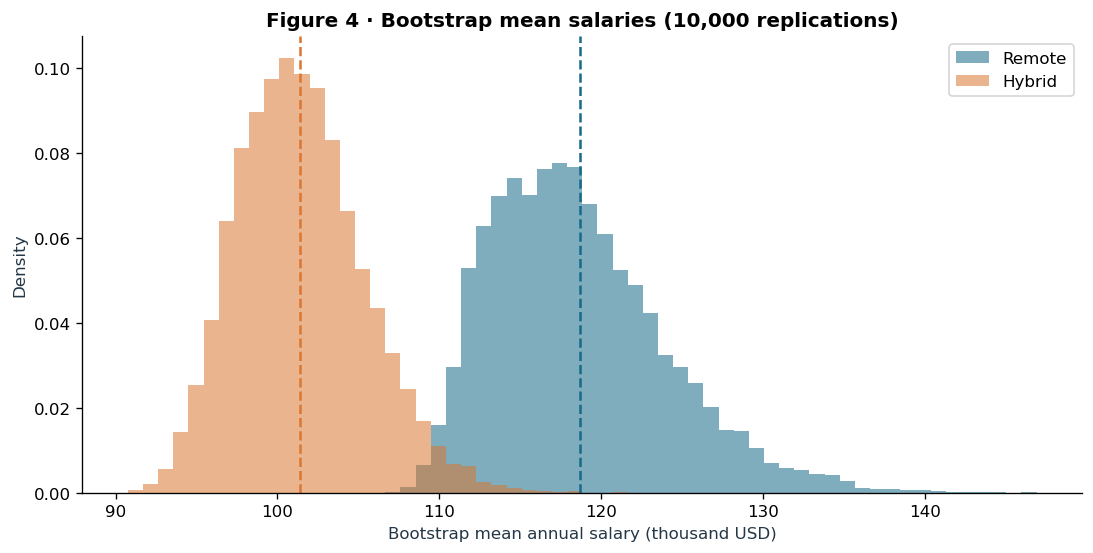

**Interpretation.** The distributions are centered near the observed means (\$118,666.90 remote and \$101,422.99 hybrid); their bootstrap SEs are \$5,362.02 and \$3,890.15. Their different spreads reflect both group size and salary dispersion; overlap alone is not a hypothesis test.

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
bins = np.histogram_bin_edges(np.r_[boot_remote['mean'], boot_hybrid['mean']]/1000, bins=60)
for name, boot, color, observed in [('Remote', boot_remote, COLORS[0], mean_remote),
                                     ('Hybrid', boot_hybrid, COLORS[1], mean_hybrid)]:
    ax.hist(boot['mean']/1000, bins=bins, density=True, color=color, alpha=.55, label=name)
    ax.axvline(observed/1000, color=color, linestyle='--', linewidth=1.5)
ax.set(xlabel='Bootstrap mean annual salary (thousand USD)', ylabel='Density',
       title='Figure 4 · Bootstrap mean salaries (10,000 replications)')
ax.legend()
show_figure(fig, 'Figure 4')
narrative(f'**Interpretation.** The distributions are centered near the observed means '
          f'({money(mean_remote)} remote and {money(mean_hybrid)} hybrid); their bootstrap '
          f'SEs are {money(boot_remote["mean"].std(ddof=1))} and '
          f'{money(boot_hybrid["mean"].std(ddof=1))}. Their different spreads reflect '
          'both group size and salary dispersion; overlap alone is not a hypothesis test.')

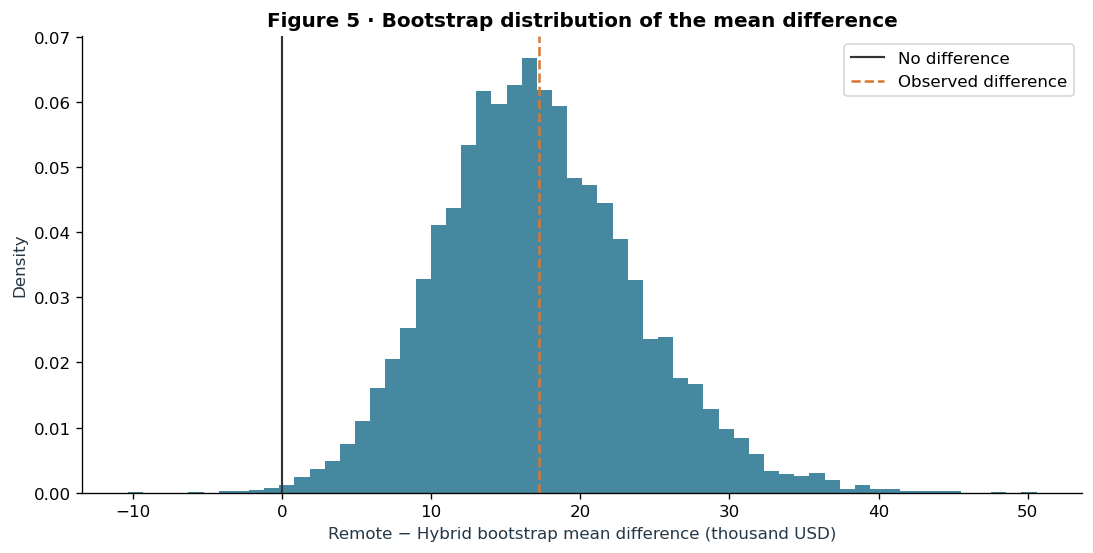

**Interpretation.** The difference distribution has center \$17,136.68, SE \$6,605.63, and skewness 0.365. Its location describes the observed gap and its spread describes uncertainty; this distribution has not imposed H0.

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
ax.hist(bootstrap_difference/1000, bins=60, color=COLORS[0], alpha=.8, density=True)
ax.axvline(0, color='#333333', linewidth=1.3, label='No difference')
ax.axvline(mean_difference/1000, color=COLORS[1], linestyle='--', label='Observed difference')
ax.set(xlabel='Remote − Hybrid bootstrap mean difference (thousand USD)', ylabel='Density',
       title='Figure 5 · Bootstrap distribution of the mean difference')
ax.legend()
show_figure(fig, 'Figure 5')
narrative(f'**Interpretation.** The difference distribution has center '
          f'{money(bootstrap_difference.mean())}, SE {money(bootstrap_difference.std(ddof=1))}, '
          f'and skewness {stats.skew(bootstrap_difference):.3f}. Its location describes the '
          'observed gap and its spread describes uncertainty; this distribution has not imposed H0.')

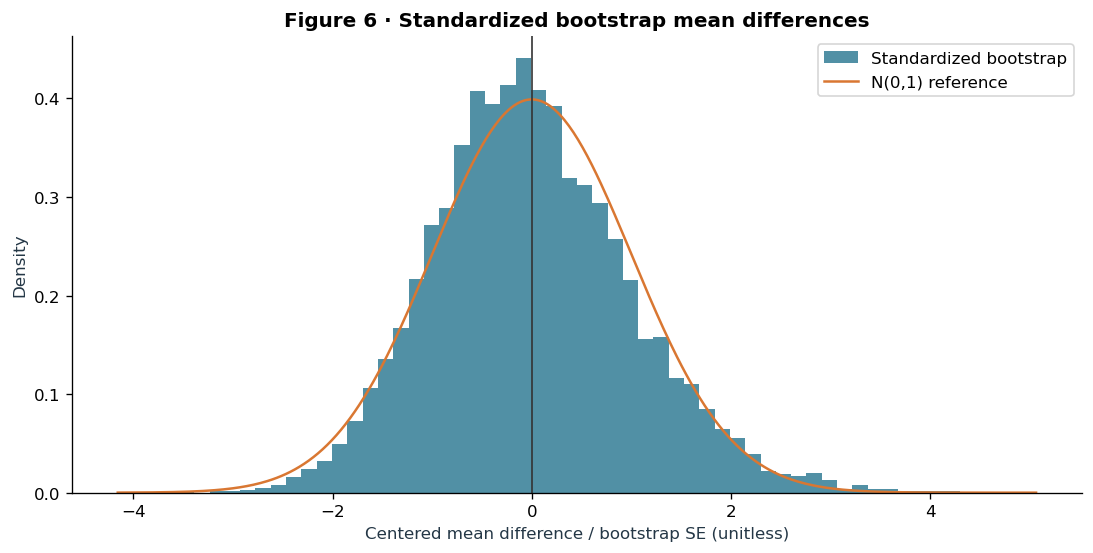

**Interpretation and pitfall.** The standardized distribution has mean zero and SD one by construction; any asymmetry or heavy tails remain. A normal overlay is a diagnostic, not proof of normality. This plot is not the studentized null distribution used next.

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
ax.hist(standardized_difference, bins=60, density=True, color=COLORS[0], alpha=.75, label='Standardized bootstrap')
grid = np.linspace(min(-4, standardized_difference.min()), max(4, standardized_difference.max()), 400)
ax.plot(grid, stats.norm.pdf(grid), color=COLORS[1], label='N(0,1) reference')
ax.axvline(0, color='#333333', linewidth=1)
ax.set(xlabel='Centered mean difference / bootstrap SE (unitless)', ylabel='Density',
       title='Figure 6 · Standardized bootstrap mean differences')
ax.legend()
show_figure(fig, 'Figure 6')
narrative('**Interpretation and pitfall.** The standardized distribution has mean zero and SD one '
          'by construction; any asymmetry or heavy tails remain. A normal overlay is a diagnostic, '
          'not proof of normality. This plot is not the studentized null distribution used next.')

## 2(d) Bootstrap-Based Two-Sample t-Test
**A. Statistical concept.** A hypothesis test needs a reference distribution satisfying the null,
rather than the ordinary bootstrap centered near the observed salary gap.
We preserve each group's empirical shape and variance, so equal means are imposed without
requiring identical distributions. This is an approximate bootstrap calibration of the same
pooled statistic, with tail sensitivity and finite-sample limitations.

**B. Formulation.** Let $\bar{x}_{pool}$ be the combined sample mean and define
$x_{gi,0}=x_{gi}-\bar{x}_g+\bar{x}_{pool}$. Both empirical populations then have equal means.
Translation does not alter within-group variance. Reusing the resampling indices from Q2(c)
is algebraically identical to resampling these shifted groups:
$$T_0^{*(b)}=\frac{\Delta^{*(b)}-\widehat\Delta}
   {s_p^{*(b)}\sqrt{1/n_R+1/n_H}},\qquad
   \widehat\Delta=\bar{x}_R-\bar{x}_H.$$
The pooled bootstrap SD $s_p^{*(b)}$ is recalculated from the two variances in replication $b$.
$$\widehat p_{boot}=\frac{1+\sum_{b=1}^B I(|T_0^{*(b)}|\ge|t_{obs}|)}{B+1}.$$
$I$ is one for an extreme replication and zero otherwise; the plus-one correction avoids zero
Monte Carlo p-values. It does not make this an exact finite-sample test. Negative shifted
residual values are acceptable reference values, not asserted real salaries.

**Required calculation on bootstrap means.** Also apply the ordinary equal-variance
two-sample t-test to the two arrays of 10,000 unshifted bootstrap means. This is
reported to address the requested calculation, but these are simulated estimates,
not new survey respondents. Its standard error shrinks with the number of replications;
its p-value is not independent population evidence. The null-shift test above is a
separate, more appropriate bootstrap calibration using the original sample sizes.


In [14]:
pooled_mean = (remote.sum()+hybrid.sum()) / (n_remote+n_hybrid)
remote_null = remote - mean_remote + pooled_mean
hybrid_null = hybrid - mean_hybrid + pooled_mean
np.testing.assert_allclose([remote_null.mean(), hybrid_null.mean()], pooled_mean, rtol=1e-12)
boot_pooled_variance = ((n_remote-1)*boot_remote['variance'] +
                        (n_hybrid-1)*boot_hybrid['variance']) / degrees_freedom
boot_pooled_se = np.sqrt(boot_pooled_variance*(1/n_remote+1/n_hybrid))
null_t = (bootstrap_difference - mean_difference) / boot_pooled_se
q2_boot_test = empirical_test(null_t, manual_t, two_sided=True)
q2_mean_tests = pd.DataFrame({
    'Method': ['Original Student t', 'Null-centered bootstrap t'],
    'Observed t': [manual_t, manual_t],
    'p-value': [ptext(manual_p), ptext(q2_boot_test['p'])],
    'Decision': [decision(manual_p), decision(q2_boot_test['p'])]
}).set_index('Method')
display(q2_mean_tests)
display(pd.Series(q2_boot_test).to_frame('Bootstrap simulation diagnostics'))
narrative(f'**Interpretation.** The bootstrap gives p={ptext(q2_boot_test["p"])} '
          f'with {q2_boot_test["exceedances"]:,}/{B:,} equally or more extreme null draws: '
          f'**{decision(q2_boot_test["p"])}**. The original Student decision '
          f'{"agrees" if (manual_p < ALPHA) == (q2_boot_test["p"] < ALPHA) else "differs"}. '
          'The null bootstrap uses the observed skewness and extreme values rather than '
          'a theoretical t tail; it can therefore give a different p-value. The Monte Carlo '
          'interval above measures simulation error only. Neither method accounts for survey-selection bias.')

bootstrap_means_t = stats.ttest_ind(boot_remote['mean'], boot_hybrid['mean'], equal_var=True)
display(pd.Series({'t on simulated means': bootstrap_means_t.statistic,
                   'df': bootstrap_means_t.df, 'p-value': ptext(bootstrap_means_t.pvalue)}).to_frame('Required bootstrap-means calculation'))
narrative('The bootstrap-means t-test rejects at 0.05, but its simulated sample size is B per group. '
          'Increasing B can make its p-value arbitrarily small without collecting more respondents; '
          'it is not independent confirmation of the original-data test.')


,Observed t,p-value,Decision
Method,,,
Original Student t,2.635,0.008421,Reject H0
Null-centered bootstrap t,2.635,0.005099,Reject H0


,Bootstrap simulation diagnostics
p,0.005
exceedances,50.000
B,"10,000.000"
MC tail lower,0.004
MC tail upper,0.007


**Interpretation.** The bootstrap gives p=0.005099 with 50/10,000 equally or more extreme null draws: **Reject H0**. The original Student decision agrees. The null bootstrap uses the observed skewness and extreme values rather than a theoretical t tail; it can therefore give a different p-value. The Monte Carlo interval above measures simulation error only. Neither method accounts for survey-selection bias.

,Required bootstrap-means calculation
t on simulated means,258.685
df,"19,998.000"
p-value,< floating-point resolution (not exactly zero)


The bootstrap-means t-test rejects at 0.05, but its simulated sample size is B per group. Increasing B can make its p-value arbitrarily small without collecting more respondents; it is not independent confirmation of the original-data test.

## 2(e) Formula-Based and Bootstrap Confidence Intervals
**A. Statistical concept.** A confidence interval conveys the magnitude and uncertainty of
the population mean gap. Under its assumptions, a 95% interval procedure covers the fixed
parameter in about 95% of hypothetical repeated samples. It is not a 95% probability assigned
to this particular fixed parameter after observing the data. Different interval methods use
different approximations and need not exactly match a separately calibrated bootstrap test.

**B. Formulation.** Keep the pooled model consistent with the required Student calculation:
$$CI_t=\widehat\Delta\pm t_{.975,\nu}SE_p.$$
Here $t_{.975,\nu}$ is the critical t quantile and the product with $SE_p$ is the margin of error.
Reuse the **ordinary**, unshifted Q2(c) differences for the percentile interval:
$$CI_{percentile}=[Q_{.025}(\Delta^*),Q_{.975}(\Delta^*)].$$
$Q_a$ denotes empirical quantile $a$. Do not subtract the endpoints of separate group
intervals or use the null distribution to estimate the salary-gap interval.

In [15]:
critical_t = stats.t.ppf(.975, degrees_freedom)
margin_of_error = critical_t * pooled_se
parametric_ci = np.array([mean_difference-margin_of_error, mean_difference+margin_of_error])
bootstrap_ci = np.quantile(bootstrap_difference, [.025, .975])
q2_cis = pd.DataFrame([parametric_ci, bootstrap_ci],
                     index=['Pooled t interval', 'Bootstrap percentile interval'], columns=['Lower USD', 'Upper USD'])
q2_cis['Width USD'] = q2_cis['Upper USD']-q2_cis['Lower USD']
q2_cis['Includes zero'] = (q2_cis['Lower USD'] <= 0) & (q2_cis['Upper USD'] >= 0)
display(pd.Series({'SE (USD)': pooled_se, 'Critical t': critical_t,
                   'Margin of error (USD)': margin_of_error}).to_frame('Formula ingredients'))
display(q2_cis)
narrative(f'**E. Interpretation.** The pooled 95% interval is '
          f'[{money(parametric_ci[0])}, {money(parametric_ci[1])}]; the bootstrap interval is '
          f'[{money(bootstrap_ci[0])}, {money(bootstrap_ci[1])}]. '
          f'Zero is {"included" if q2_cis.iloc[0]["Includes zero"] else "excluded"} by the pooled interval '
          f'and {"included" if q2_cis.iloc[1]["Includes zero"] else "excluded"} by the bootstrap interval. '
          f'The interval conclusions {"agree" if q2_cis["Includes zero"].nunique()==1 else "differ"}. '
          'Skewness, outliers, pooled versus empirical variance estimates and Monte Carlo error '
          'can explain differences. The endpoints quantify an unadjusted salary gap, not the '
          'income an individual would gain by switching work mode.')

,Formula ingredients
SE (USD),"6,543.986"
Critical t,1.960
Margin of error (USD),"12,827.035"


,Lower USD,Upper USD,Width USD,Includes zero
Pooled t interval,"4,416.876","30,070.947","25,654.070",False
Bootstrap percentile interval,"5,247.875","31,125.756","25,877.881",False


**E. Interpretation.** The pooled 95% interval is [\$4,416.88, \$30,070.95]; the bootstrap interval is [\$5,247.87, \$31,125.76]. Zero is excluded by the pooled interval and excluded by the bootstrap interval. The interval conclusions agree. Skewness, outliers, pooled versus empirical variance estimates and Monte Carlo error can explain differences. The endpoints quantify an unadjusted salary gap, not the income an individual would gain by switching work mode.

## 2(f) Mood's Median Test and Bootstrap Median Comparison
**A. Statistical concept.** The median is less sensitive than the mean to the magnitude of
extreme salaries. Mood's nonparametric median test classifies salaries above or at/below the
combined median and tests the resulting $2\times2$ contingency table. It discards distance
information and can have less power than procedures using more of the distribution.
Nonparametric does not mean assumption-free: independent observations and adequate expected
cell counts are required, and salary rounding/ties can matter.

**B. Formulation.** Let $m_R,m_H$ denote population medians and $\tilde{x}_R,\tilde{x}_H$
their sample estimates. Test $H_0:m_R-m_H=0$ against $H_1:m_R-m_H\ne0$.
With the combined median $\tilde{x}_{pool}$, Mood's test uses observed counts $O_{ij}$ and
independence-model expected counts $E_{ij}=(\text{row total})(\text{column total})/N$.
The uncorrected Pearson statistic is $\sum_{ij}(O_{ij}-E_{ij})^2/E_{ij}$ with one degree of
freedom; here SciPy applies **Yates' continuity correction** and assigns ties **below**.

For the bootstrap, shift each group to the common median:
$x_{gi,0}=x_{gi}-\tilde{x}_g+\tilde{x}_{pool}$, preserving its empirical shape.
Draw 10,000 n-out-of-n samples per group and exploit translation equivariance:
$$D_{med,0}^{*(b)}=(\tilde{x}_R^{*(b)}-\tilde{x}_H^{*(b)})
                   -(\tilde{x}_R-\tilde{x}_H).$$
Compare $|D_{med,0}^{*(b)}|$ with the observed absolute median gap using the plus-one tail
formula from Q2(d). This unstudentized, null-centered median bootstrap is an approximate
test under regular, locally continuous distributions with positive density near each median.
Rounded/discrete salaries and ties weaken that approximation; report them and compare
Mood's alternative tie conventions as a diagnostic rather than force agreement.

In [16]:
median_remote, median_hybrid = np.median(remote), np.median(hybrid)
median_difference = median_remote - median_hybrid
mood = stats.median_test(remote, hybrid, ties='below', correction=True)
contingency = pd.DataFrame(mood.table, index=['Above combined median', 'At/below combined median'],
                           columns=['Remote', 'Hybrid'])
expected_counts = stats.contingency.expected_freq(mood.table)
display(contingency)
display(pd.Series({'Remote median (USD)': median_remote, 'Hybrid median (USD)': median_hybrid,
                   'Difference (USD)': median_difference, 'Combined median (USD)': mood.median,
                   'Remote ties at combined median': np.sum(remote == mood.median),
                   'Hybrid ties at combined median': np.sum(hybrid == mood.median),
                   'Minimum expected cell count': expected_counts.min(),
                   'Mood chi-square (Yates corrected)': mood.statistic,
                   'Mood p-value': ptext(mood.pvalue)}).to_frame('Median test details'))
median_boot_remote = bootstrap_summary(remote, streams['median_remote'], include_median=True)
median_boot_hybrid = bootstrap_summary(hybrid, streams['median_hybrid'], include_median=True)
bootstrap_median_difference = median_boot_remote['median'] - median_boot_hybrid['median']
null_median_difference = bootstrap_median_difference - median_difference
np.testing.assert_allclose([np.median(remote-median_remote+mood.median),
                           np.median(hybrid-median_hybrid+mood.median)], mood.median)
q2_median_boot_test = empirical_test(null_median_difference, median_difference, two_sided=True)
q2_median_tests = pd.DataFrame({
    'Method': ["Mood's median test", 'Null-centered median bootstrap'],
    'p-value': [ptext(mood.pvalue), ptext(q2_median_boot_test['p'])],
    'Decision': [decision(mood.pvalue), decision(q2_median_boot_test['p'])]
}).set_index('Method')
display(q2_median_tests)
display(pd.Series(q2_median_boot_test).to_frame('Bootstrap simulation diagnostics'))
display(pd.DataFrame([
    {'Tie rule (diagnostic)': rule, 'Mood p-value': ptext(stats.median_test(remote, hybrid, ties=rule, correction=True).pvalue)}
    for rule in ['below', 'above', 'ignore']
]))
narrative(f'**Interpretation.** The observed median gap is **{money(median_difference)}** '
          f'({money(median_remote)} remote versus {money(median_hybrid)} hybrid). '
          f'Mood’s p={ptext(mood.pvalue)} and bootstrap p={ptext(q2_median_boot_test["p"])} '
          f'give {"the same" if (mood.pvalue < ALPHA)==(q2_median_boot_test["p"] < ALPHA) else "different"} '
          'significance decisions. Their numerical p-values are not estimates of identical tail '
          'probabilities: Mood uses threshold counts and a chi-square approximation, whereas '
          'the bootstrap calibrates a dollar-valued median gap using the empirical distributions.')
if q2_median_boot_test['exceedances'] == 0:
    narrative(f'**Resolution limitation.** No simulated median-null gap was as extreme as the observed '
              f'gap. The reported p={1/(B+1):.5g} is the plus-one reporting floor, not a precise '
              f'estimate of the true tail probability. The exact 95% Monte Carlo upper bound is '
              f'{q2_median_boot_test["MC tail upper"]:.5g}; 10,000 replications cannot resolve '
              'a p-value as tiny as the analytical Mood result.')

,Remote,Hybrid
Above combined median,3755,3566
At/below combined median,3133,4210


,Median test details
Remote median (USD),"90,491.000"
Hybrid median (USD),"77,730.000"
Difference (USD),"12,761.000"
Combined median (USD),"81,870.000"
Remote ties at combined median,11
Hybrid ties at combined median,5
Minimum expected cell count,"3,438.833"
Mood chi-square (Yates corrected),109.124
Mood p-value,1.524e-25


,p-value,Decision
Method,,
Mood's median test,1.524e-25,Reject H0
Null-centered median bootstrap,9.999e-05,Reject H0


,Bootstrap simulation diagnostics
p,9.9990e-05
exceedances,0.000
B,"10,000.000"
MC tail lower,0.000
MC tail upper,3.6882e-04


,Tie rule (diagnostic),Mood p-value
0,below,1.524e-25
1,above,4.491e-26
2,ignore,7.775e-26


**Interpretation.** The observed median gap is **\$12,761.00** (\$90,491.00 remote versus \$77,730.00 hybrid). Mood’s p=1.524e-25 and bootstrap p=9.999e-05 give the same significance decisions. Their numerical p-values are not estimates of identical tail probabilities: Mood uses threshold counts and a chi-square approximation, whereas the bootstrap calibrates a dollar-valued median gap using the empirical distributions.

**Resolution limitation.** No simulated median-null gap was as extreme as the observed gap. The reported p=9.999e-05 is the plus-one reporting floor, not a precise estimate of the true tail probability. The exact 95% Monte Carlo upper bound is 0.00036882; 10,000 replications cannot resolve a p-value as tiny as the analytical Mood result.

## 2(g) Summary of Question 2 Findings
The next table consolidates the full-salary primary analyses. The IQR sensitivity comparison
and Welch result remain supporting diagnostics, not replacements selected after seeing significance.

In [17]:
q2_summary = pd.DataFrame([
    {'Target': 'Mean', 'Method': 'Pooled Student t', 'Gap USD (R−H)': mean_difference,
     'p-value': ptext(manual_p), 'Decision': decision(manual_p)},
    {'Target': 'Mean', 'Method': 'Null-centered bootstrap t', 'Gap USD (R−H)': mean_difference,
     'p-value': ptext(q2_boot_test['p']), 'Decision': decision(q2_boot_test['p'])},
    {'Target': 'Median', 'Method': "Mood's median test", 'Gap USD (R−H)': median_difference,
     'p-value': ptext(mood.pvalue), 'Decision': decision(mood.pvalue)},
    {'Target': 'Median', 'Method': 'Null-centered median bootstrap', 'Gap USD (R−H)': median_difference,
     'p-value': ptext(q2_median_boot_test['p']), 'Decision': decision(q2_median_boot_test['p'])}
])
display(q2_summary)
narrative('**Interpretation.** Means and medians address different population features; agreement '
          'between their decisions does not make the tests interchangeable. All estimates remain '
          'global, unadjusted comparisons of the two observed work-mode groups. Country, occupation, '
          'experience, seniority and employer characteristics can confound these associations.')

,Target,Method,Gap USD (R−H),p-value,Decision
0,Mean,Pooled Student t,"17,243.912",0.008421,Reject H0
1,Mean,Null-centered bootstrap t,"17,243.912",0.005099,Reject H0
2,Median,Mood's median test,"12,761.000",1.524e-25,Reject H0
3,Median,Null-centered median bootstrap,"12,761.000",9.999e-05,Reject H0


**Interpretation.** Means and medians address different population features; agreement between their decisions does not make the tests interchangeable. All estimates remain global, unadjusted comparisons of the two observed work-mode groups. Country, occupation, experience, seniority and employer characteristics can confound these associations.

# 3. Question 3 — Education-Level Salary Comparisons
## 3(a) Data Preparation and Descriptive Statistics
**Concept.** Grouped descriptive statistics provide the same location, dispersion and tail
checks as Q2(a), now across three education categories. Conditioning on country defines a
different analysis population and must occur before the education comparison. Unequal group
sizes affect precision, especially when the smallest group has the greatest variability.
Within the selected population, retain all positive finite salaries in the primary analysis and report group-specific IQR
diagnostics, with an explicitly separate exclusion sensitivity comparison.

**Verified definitions.** Country must equal `United States of America` or `Canada`.
Education must equal `Bachelor's degree`, `Master's degree`, or `Professional degree`.
“Professional” is the cleaned file's label; we do not infer an unprovided degree composition.

In [18]:
na_mask = survey.Country.isin(north_america)
degree_mask = survey.EdLevel.isin(education_labels)
q3_data = survey.loc[na_mask & degree_mask, ['Country', 'EdLevel', SALARY]].copy()
education_groups = {name: q3_data.loc[q3_data.EdLevel.eq(name), SALARY].to_numpy(float)
                    for name in education_labels}
group_sizes = np.array([len(x) for x in education_groups.values()])
education_means = np.array([x.mean() for x in education_groups.values()])
education_variances = np.array([x.var(ddof=1) for x in education_groups.values()])
q3_descriptives = summary_table(education_groups)
q3_outliers = outlier_table(education_groups)
display(pd.Series({'All survey rows': len(survey), 'Outside US/Canada': (~na_mask).sum(),
                   'US/Canada rows': na_mask.sum(),
                   'US/Canada, other degrees': (na_mask & ~degree_mask).sum(),
                   'Final Q3 rows': len(q3_data)}).to_frame('Filter accounting'))
display(pd.crosstab(q3_data.EdLevel, q3_data.Country).reindex(education_labels))
display(q3_descriptives.T.rename_axis('Statistic (USD unless stated)'))
display(q3_outliers)
education_trimmed = {name: within_iqr(x) for name, x in education_groups.items()}
q3_sensitivity = pd.DataFrame({
    'Primary n': group_sizes, 'Primary mean': education_means,
    'IQR-restricted n': [len(x) for x in education_trimmed.values()],
    'IQR-restricted mean': [x.mean() for x in education_trimmed.values()]
}, index=education_labels)
display(q3_sensitivity)
narrative(f'**Interpretation.** The degree groups contain {group_sizes[0]:,}, {group_sizes[1]:,} '
          f'and {group_sizes[2]:,} respondents respectively. Their means are '
          f'{money(education_means[0])}, {money(education_means[1])} and '
          f'{money(education_means[2])}. Smaller groups and larger dispersion can widen '
          'uncertainty even when their observed means are higher. The IQR sensitivity means '
          'describe truncated groups; no exclusions from that comparison enter the required tests.')

,Filter accounting
All survey rows,20312
Outside US/Canada,14899
US/Canada rows,5413
"US/Canada, other degrees",1097
Final Q3 rows,4316


Country,Canada,United States of America
EdLevel,,
Bachelor's degree,406,2548
Master's degree,133,934
Professional degree,35,260


,Bachelor's degree,Master's degree,Professional degree
Statistic (USD unless stated),,,
n,"2,954.000","1,067.000",295.000
Mean,"161,010.573","183,133.081","199,595.753"
Median,"140,000.000","160,000.000","160,000.000"
SD,"114,048.104","162,860.316","196,280.637"
Variance (USD²),"13,006,970,063.611","26,523,482,587.864","38,526,088,547.289"
Minimum,126.000,125.000,185.000
Q1,"100,000.000","112,000.000","109,438.000"
Q3,"190,000.000","216,500.000","218,500.000"
IQR,"90,000.000","104,500.000","109,062.000"


,Lower fence,Upper fence,Flagged n,Flagged %,Skewness,Largest share of sum %
Bachelor's degree,"-35,000.000","325,000.000",151.000,5.112,4.771,0.410
Master's degree,"-44,750.000","373,250.000",54.000,5.061,12.120,1.996
Professional degree,"-54,155.000","382,093.000",21.000,7.119,5.943,3.984


,Primary n,Primary mean,IQR-restricted n,IQR-restricted mean
Bachelor's degree,2954,"161,010.573",2803,"142,251.756"
Master's degree,1067,"183,133.081",1013,"160,662.592"
Professional degree,295,"199,595.753",274,"160,710.755"


**Interpretation.** The degree groups contain 2,954, 1,067 and 295 respondents respectively. Their means are \$161,010.57, \$183,133.08 and \$199,595.75. Smaller groups and larger dispersion can widen uncertainty even when their observed means are higher. The IQR sensitivity means describe truncated groups; no exclusions from that comparison enter the required tests.

## 3(b) One-Way ANOVA
**A. Statistical concept.** ANOVA tests equality of all three population means in one omnibus
comparison. It avoids replacing the requested question with three unadjusted t-tests, which
would increase family-wise false positives. The F statistic measures between-group variation
relative to within-group variation. Ordinary ANOVA assumes independent observations,
equal population variances, and normal within-group errors for its exact F reference;
large groups can help approximate inference but do not erase heavy-tail or selection concerns.

**B. Formulation.** With $k=3$ groups, total count $N$, group sizes $n_g$, group means
$\bar{x}_g$, and weighted overall mean $\bar{x}$:
$$H_0:\mu_B=\mu_M=\mu_P,\qquad H_1:\text{at least one mean differs}.$$
$$F=\frac{\sum_g n_g(\bar{x}_g-\bar{x})^2/(k-1)}
              {\sum_g(n_g-1)s_g^2/(N-k)}.$$
The numerator and denominator are the between- and within-group mean squares.
Under the classical null assumptions, $F\sim F_{k-1,N-k}$ and the upper tail provides the p-value.
The primary calculation uses SciPy; a sum-of-squares check validates its degrees of freedom
and statistic. A significant omnibus result does not identify which pair differs.

**Variance robustness.** Because unequal variances and unequal sizes can interact, also report
Welch's one-way ANOVA. For compatibility with SciPy versions before 1.16, implement its
published summary-statistic formula directly: let $w_g=n_g/s_g^2$, $W=\sum_gw_g$,
$\bar{x}_w=\sum_g w_g\bar{x}_g/W$ and $A=\sum_g(1-w_g/W)^2/(n_g-1)$.
Then $F_W=[\sum_gw_g(\bar{x}_g-\bar{x}_w)^2/(k-1)]/[1+2(k-2)A/(k^2-1)]$,
with degrees of freedom $k-1$ and $(k^2-1)/(3A)$. This supplement does not replace ordinary ANOVA.

In [19]:
anova = stats.f_oneway(*education_groups.values())
k = len(education_groups)
total_n = int(group_sizes.sum())
df_between, df_within = k-1, total_n-k
grand_mean = np.average(education_means, weights=group_sizes)
ss_between = np.sum(group_sizes*(education_means-grand_mean)**2)
ss_within = np.sum((group_sizes-1)*education_variances)
checked_f = (ss_between/df_between)/(ss_within/df_within)
np.testing.assert_allclose(checked_f, anova.statistic, rtol=1e-12)
np.testing.assert_allclose(stats.f.sf(checked_f, df_between, df_within), anova.pvalue, rtol=1e-12)
q3_levene = stats.levene(*education_groups.values(), center='median')
variance_ratio_q3 = education_variances.max()/education_variances.min()
welch_weights = group_sizes / education_variances
welch_weighted_mean = np.average(education_means, weights=welch_weights)
welch_A = np.sum((1-welch_weights/welch_weights.sum())**2/(group_sizes-1))
welch_f = (np.sum(welch_weights*(education_means-welch_weighted_mean)**2)/(k-1)) / (1+2*(k-2)*welch_A/(k*k-1))
welch_df2 = (k*k-1)/(3*welch_A)
welch_anova_p = stats.f.sf(welch_f, k-1, welch_df2)
trimmed_anova = stats.f_oneway(*education_trimmed.values())
q3_anova_results = pd.DataFrame({
    'Method': ['Ordinary ANOVA (primary)', 'Welch ANOVA (robustness)', 'IQR-restricted ANOVA (sensitivity)'],
    'F': [anova.statistic, welch_f, trimmed_anova.statistic],
    'Numerator df': [df_between]*3,
    'Denominator df': [df_within, welch_df2, sum(map(len, education_trimmed.values()))-k],
    'p-value': [ptext(anova.pvalue), ptext(welch_anova_p), ptext(trimmed_anova.pvalue)],
    'Decision': [decision(p) for p in [anova.pvalue, welch_anova_p, trimmed_anova.pvalue]]
}).set_index('Method')
display(q3_anova_results)
narrative(f'**E. Interpretation.** Ordinary ANOVA gives F({df_between}, {df_within})='
          f'{anova.statistic:.4f}, p={ptext(anova.pvalue)}: **{decision(anova.pvalue)}**. '
          f'The variance ratio is {variance_ratio_q3:.2f} and median-centered Levene '
          f'p={ptext(q3_levene.pvalue)}. Welch’s variance-robust p={ptext(welch_anova_p)} '
          f'leads to {decision(welch_anova_p)}. The IQR-restricted p='
          f'{ptext(trimmed_anova.pvalue)} quantifies sensitivity to truncation. '
          'The classical F p-value needs caution where equal variances are doubtful; '
          'the null bootstrap below supplies a separate empirical calibration. '
          'No pair-specific significance or causal effect of education follows from this omnibus test.')

,F,Numerator df,Denominator df,p-value,Decision
Method,,,,,
Ordinary ANOVA (primary),18.736,2,"4,313.000",7.909e-09,Reject H0
Welch ANOVA (robustness),12.976,2,682.266,2.944e-06,Reject H0
IQR-restricted ANOVA (sensitivity),34.897,2,"4,087.000",9.382e-16,Reject H0


**E. Interpretation.** Ordinary ANOVA gives F(2, 4313)=18.7362, p=7.909e-09: **Reject H0**. The variance ratio is 2.96 and median-centered Levene p=1.626e-05. Welch’s variance-robust p=2.944e-06 leads to Reject H0. The IQR-restricted p=9.382e-16 quantifies sensitivity to truncation. The classical F p-value needs caution where equal variances are doubtful; the null bootstrap below supplies a separate empirical calibration. No pair-specific significance or causal effect of education follows from this omnibus test.

## 3(c) Bootstrap Analysis and Three Required Figures
**A. Statistical concept.** Independently bootstrap each degree group at its own size to
represent uncertainty in each mean. Pairwise differences describe how these estimates
compare in dollars. Standardization separates differences in location and spread from
differences in shape, but does not test equality of the three means.

**B. Formulation.** For each of 10,000 replications, form
$\Delta_{BM}^*=\bar{x}_B^*-\bar{x}_M^*$,
$\Delta_{BP}^*=\bar{x}_B^*-\bar{x}_P^*$ and
$\Delta_{MP}^*=\bar{x}_M^*-\bar{x}_P^*$.
Standardize each pair $j$ separately using
$z_j^*=(\Delta_j^*-\overline{\Delta_j^*})/s_{\Delta_j^*}$.
Here B, M and P denote Bachelor's, Master's and Professional degrees; starred means are
bootstrap estimates. Shared group draws make pairwise contrasts dependent, as they should be.
These plots are descriptive uncertainty summaries, **not three unadjusted significance tests**.

In [20]:
education_boot = {label: bootstrap_summary(education_groups[label], streams[stream])
                  for label, stream in zip(education_labels, ['bachelor', 'master', 'professional'])}
boot_education_means = np.column_stack([education_boot[label]['mean'] for label in education_labels])
boot_education_variances = np.column_stack([education_boot[label]['variance'] for label in education_labels])
pair_indices = [(0, 1), (0, 2), (1, 2)]
pair_names = ["Bachelor's − Master's", "Bachelor's − Professional", "Master's − Professional"]
education_differences = {name: boot_education_means[:, i]-boot_education_means[:, j]
                         for name, (i, j) in zip(pair_names, pair_indices)}
education_standardized = {name: standardize(x) for name, x in education_differences.items()}
observed_pair_differences = {name: education_means[i]-education_means[j]
                            for name, (i, j) in zip(pair_names, pair_indices)}
q3_boot_summary = pd.DataFrame({
    'Observed mean USD': education_means,
    'Bootstrap center USD': boot_education_means.mean(axis=0),
    'Bootstrap SE USD': boot_education_means.std(axis=0, ddof=1)
}, index=education_labels)
q3_pair_summary = pd.DataFrame({
    'Observed difference USD': observed_pair_differences,
    'Bootstrap center USD': {name: x.mean() for name, x in education_differences.items()},
    'Bootstrap SE USD': {name: x.std(ddof=1) for name, x in education_differences.items()},
    'Bootstrap skewness': {name: stats.skew(x) for name, x in education_differences.items()}
})
display(q3_boot_summary)
display(q3_pair_summary)

,Observed mean USD,Bootstrap center USD,Bootstrap SE USD
Bachelor's degree,"161,010.573","161,010.609","2,100.561"
Master's degree,"183,133.081","183,123.868","5,000.739"
Professional degree,"199,595.753","199,854.717","11,546.905"


,Observed difference USD,Bootstrap center USD,Bootstrap SE USD,Bootstrap skewness
Bachelor's − Master's,"-22,122.508","-22,113.259","5,417.630",-0.299
Bachelor's − Professional,"-38,585.180","-38,844.107","11,747.647",-0.347
Master's − Professional,"-16,462.672","-16,730.848","12,632.668",-0.235


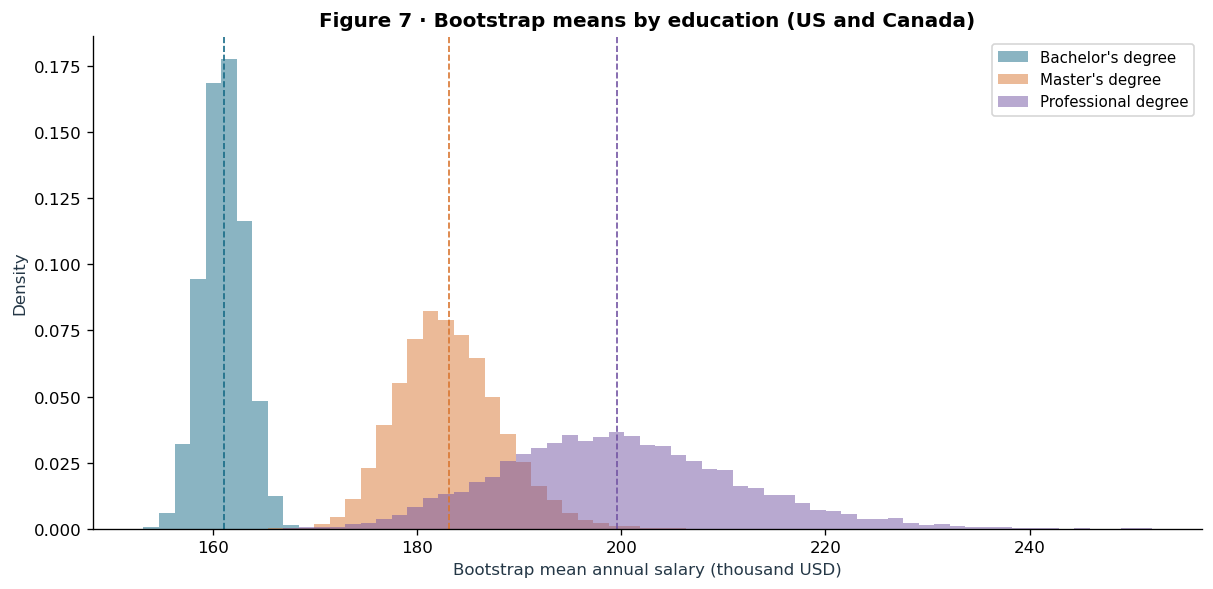

**Interpretation.** Professional degree has the widest mean-salary bootstrap distribution (SE \$11,546.91). Group-size imbalance and salary dispersion both affect precision; apparent separation or overlap is not a substitute for the omnibus test.

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.8), layout='constrained')
bins = np.histogram_bin_edges(boot_education_means.ravel()/1000, bins=65)
for i, (label, color) in enumerate(zip(education_labels, COLORS)):
    ax.hist(boot_education_means[:, i]/1000, bins=bins, density=True, alpha=.5, color=color, label=label)
    ax.axvline(education_means[i]/1000, color=color, linestyle='--', linewidth=1)
ax.set(xlabel='Bootstrap mean annual salary (thousand USD)', ylabel='Density',
       title='Figure 7 · Bootstrap means by education (US and Canada)')
ax.legend(fontsize=9)
show_figure(fig, 'Figure 7')
widest = q3_boot_summary['Bootstrap SE USD'].idxmax()
narrative(f'**Interpretation.** {widest} has the widest mean-salary bootstrap distribution '
          f'(SE {money(q3_boot_summary.loc[widest, "Bootstrap SE USD"])}). '
          'Group-size imbalance and salary dispersion both affect precision; apparent separation '
          'or overlap is not a substitute for the omnibus test.')

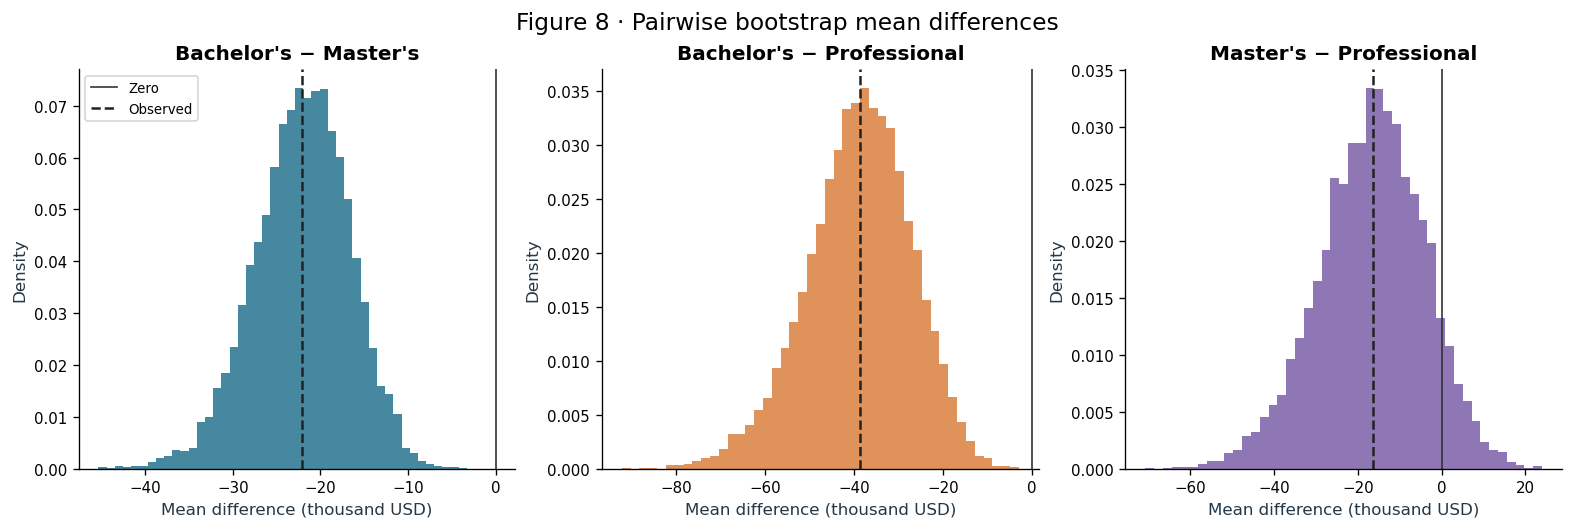

**Interpretation.** Observed contrasts are Bachelor's − Master's: -\$22,122.51; Bachelor's − Professional: -\$38,585.18; Master's − Professional: -\$16,462.67. Their distributions have different spreads, so the largest observed gap need not be the most precise. These are unadjusted descriptive contrasts; no pairwise significance is claimed.

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), layout='constrained')
for ax, (name, x), color in zip(axes, education_differences.items(), COLORS):
    ax.hist(x/1000, bins=45, density=True, color=color, alpha=.8)
    ax.axvline(0, color='#333333', linewidth=1, label='Zero')
    ax.axvline(observed_pair_differences[name]/1000, color='#222222', linestyle='--', label='Observed')
    ax.set(title=name, xlabel='Mean difference (thousand USD)', ylabel='Density')
    ax.tick_params(axis='both', labelsize=9)
axes[0].legend(fontsize=8)
fig.suptitle('Figure 8 · Pairwise bootstrap mean differences', fontsize=14)
show_figure(fig, 'Figure 8')
narrative('**Interpretation.** Observed contrasts are ' + '; '.join(
    f'{name}: {money(value)}' for name, value in observed_pair_differences.items()) +
    '. Their distributions have different spreads, so the largest observed gap need not be '
    'the most precise. These are unadjusted descriptive contrasts; no pairwise significance is claimed.')

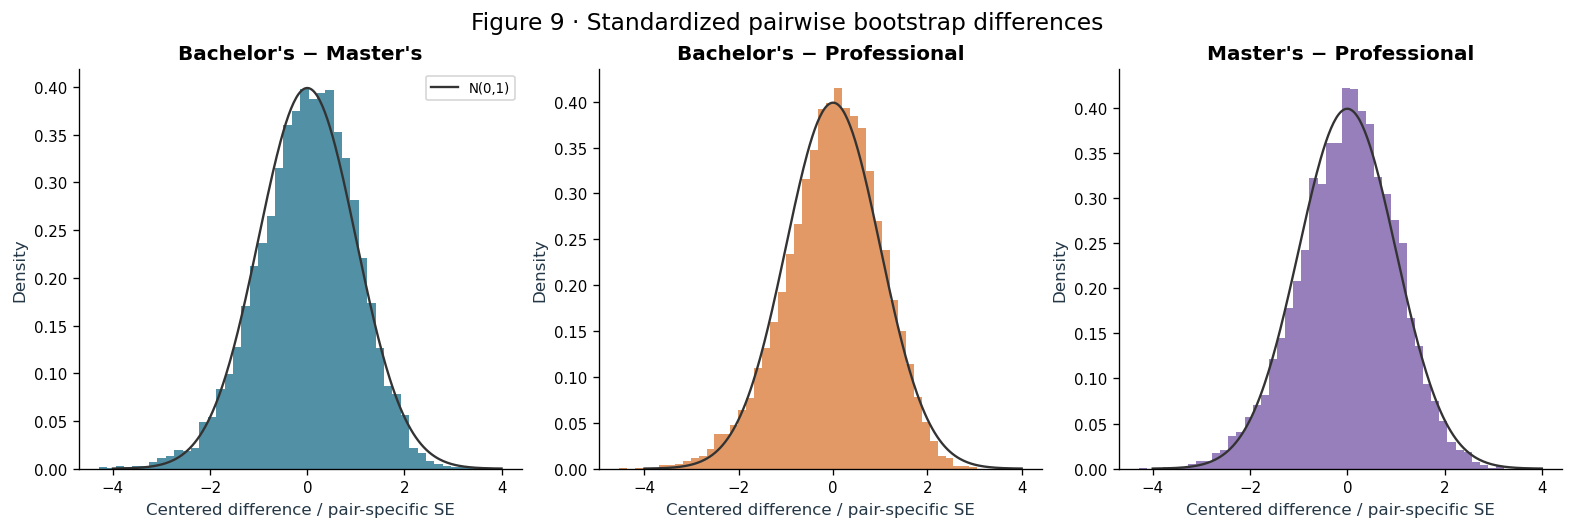

**Interpretation.** Each distribution is centered at zero with SD one using its own bootstrap spread. Remaining asymmetry reflects the underlying resampling behavior; centering removes the estimated dollar gap and cannot establish equal population means. The three pairwise z distributions are not ANOVA F statistics.

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), layout='constrained')
grid = np.linspace(-4, 4, 300)
for ax, (name, x), color in zip(axes, education_standardized.items(), COLORS):
    ax.hist(x, bins=45, density=True, color=color, alpha=.75)
    ax.plot(grid, stats.norm.pdf(grid), color='#333333', linewidth=1.4, label='N(0,1)')
    ax.set(title=name, xlabel='Centered difference / pair-specific SE', ylabel='Density')
    ax.tick_params(axis='both', labelsize=9)
axes[0].legend(fontsize=8)
fig.suptitle('Figure 9 · Standardized pairwise bootstrap differences', fontsize=14)
show_figure(fig, 'Figure 9')
narrative('**Interpretation.** Each distribution is centered at zero with SD one using its '
          'own bootstrap spread. Remaining asymmetry reflects the underlying resampling behavior; '
          'centering removes the estimated dollar gap and cannot establish equal population means. '
          'The three pairwise z distributions are not ANOVA F statistics.')

## 3(d) Bootstrap-Based ANOVA
**A. Statistical concept.** Calibrate the omnibus F statistic against data generated under
equal group means. Shift each degree group to a common mean while retaining its empirical
variance and shape, then bootstrap groups independently at their own sizes. This tests a
mean-equality null without pooling salaries into a single identical-distribution null.
It approximates the sampling distribution conditional on the empirical populations and
cannot compensate for unobserved extremes, survey dependence or systematic selection.

**B. Formulation.** Set $x_{gi,0}=x_{gi}-\bar{x}_g+\bar{x}$, where $\bar{x}$ is the
combined mean. For each replication compute F with the same between/within formula from 3(b).
Translation preserves variances, so use Q3(c)'s stored variances and shift its bootstrap
means by $\bar{x}-\bar{x}_g$; this is exactly the same operation as resampling shifted data.
$$\widehat p_F=\frac{1+\sum_{b=1}^{10000}I(F_0^{*(b)}\ge F_{obs})}{10001}.$$
Use the **upper** tail because large between/within variation signals unequal means,
not merely because F is nonnegative. The ordinary ANOVA on the arrays of 10,000 means is reported separately below only as the required simulation-based calculation, with its pseudoreplication limitation.

In [24]:
education_null_groups = {label: x-x.mean()+grand_mean for label, x in education_groups.items()}
np.testing.assert_allclose([x.mean() for x in education_null_groups.values()], grand_mean, rtol=1e-12)
null_education_means = boot_education_means - education_means + grand_mean
null_grand_means = np.average(null_education_means, weights=group_sizes, axis=1)
null_ss_between = np.sum(group_sizes*(null_education_means-null_grand_means[:, None])**2, axis=1)
null_ss_within = np.sum((group_sizes-1)*boot_education_variances, axis=1)
null_f = (null_ss_between/df_between)/(null_ss_within/df_within)
q3_boot_test = empirical_test(null_f, anova.statistic)
q3_mean_tests = pd.DataFrame({
    'Method': ['Original ordinary ANOVA', 'Null-centered bootstrap F'],
    'Observed F': [anova.statistic, anova.statistic],
    'p-value': [ptext(anova.pvalue), ptext(q3_boot_test['p'])],
    'Decision': [decision(anova.pvalue), decision(q3_boot_test['p'])]
}).set_index('Method')
display(q3_mean_tests)
display(pd.Series(q3_boot_test).to_frame('Bootstrap simulation diagnostics'))
narrative(f'**E. Interpretation.** The empirical F test gives p={ptext(q3_boot_test["p"])} '
          f'(extreme-draw count: {q3_boot_test["exceedances"]:,} out of {B:,}): '
          f'**{decision(q3_boot_test["p"])}**. This '
          f'{"agrees" if (q3_boot_test["p"] < ALPHA)==(anova.pvalue < ALPHA) else "disagrees"} '
          'with the classical decision. The bootstrap preserves unequal empirical variances '
          'and tail shapes, whereas the theoretical F reference assumes equal variances. '
          'A difference in p-values can therefore reflect calibration as well as Monte Carlo noise. '
          'Rejection supports at least one mean difference, not an ordering of significant pairwise effects. '
          'With very few extreme draws, the Monte Carlo interval is wide relative to the estimated '
          'tail probability; 10,000 replications cannot quantify a tail as small as the classical ANOVA p-value.')

bootstrap_means_anova = stats.f_oneway(*(education_boot[label]['mean'] for label in education_labels))
display(pd.Series({'F on simulated means': bootstrap_means_anova.statistic,
                   'df between': 2, 'df within': 3*B-3,
                   'p-value': ptext(bootstrap_means_anova.pvalue)}).to_frame('Required bootstrap-means ANOVA'))
narrative('This calculation rejects at 0.05 but treats simulated means as observations. '
          'Its F statistic and p-value depend on B; it adds no respondents or independent evidence. '
          'Neither this ANOVA nor the original omnibus test identifies significant pairs.')


,Observed F,p-value,Decision
Method,,,
Original ordinary ANOVA,18.736,7.909e-09,Reject H0
Null-centered bootstrap F,18.736,9.999e-05,Reject H0


,Bootstrap simulation diagnostics
p,9.9990e-05
exceedances,0.000
B,"10,000.000"
MC tail lower,0.000
MC tail upper,3.6882e-04


**E. Interpretation.** The empirical F test gives p=9.999e-05 (extreme-draw count: 0 out of 10,000): **Reject H0**. This agrees with the classical decision. The bootstrap preserves unequal empirical variances and tail shapes, whereas the theoretical F reference assumes equal variances. A difference in p-values can therefore reflect calibration as well as Monte Carlo noise. Rejection supports at least one mean difference, not an ordering of significant pairwise effects. With very few extreme draws, the Monte Carlo interval is wide relative to the estimated tail probability; 10,000 replications cannot quantify a tail as small as the classical ANOVA p-value.

,Required bootstrap-means ANOVA
F on simulated means,"69,977.613"
df between,2
df within,29997
p-value,< floating-point resolution (not exactly zero)


This calculation rejects at 0.05 but treats simulated means as observations. Its F statistic and p-value depend on B; it adds no respondents or independent evidence. Neither this ANOVA nor the original omnibus test identifies significant pairs.

## 3(e) Summary of Question 3 Findings
The ordinary ANOVA, variance-robust check and null bootstrap address the same omnibus
equality-of-means question through different approximations. The descriptive ordering of
degree means should remain separate from pair-specific inference. Restricting to the US and
Canada reduces one source of variation but does not control country mix, occupation,
experience, seniority or employer characteristics within degree groups.

In [25]:
display(q3_descriptives[['n', 'Mean', 'Median', 'SD']])
display(q3_mean_tests)
narrative(f'**Consolidated result.** The largest observed degree-group mean is '
          f'{money(education_means.max())} ({education_labels[int(education_means.argmax())]}). '
          f'Classical ANOVA p={ptext(anova.pvalue)}, Welch p={ptext(welch_anova_p)}, '
          f'and bootstrap F p={ptext(q3_boot_test["p"])} should be reported together '
          'with the variance imbalance and the scope of the filtered population.')

,n,Mean,Median,SD
Bachelor's degree,"2,954.000","161,010.573","140,000.000","114,048.104"
Master's degree,"1,067.000","183,133.081","160,000.000","162,860.316"
Professional degree,295.000,"199,595.753","160,000.000","196,280.637"


,Observed F,p-value,Decision
Method,,,
Original ordinary ANOVA,18.736,7.909e-09,Reject H0
Null-centered bootstrap F,18.736,9.999e-05,Reject H0


**Consolidated result.** The largest observed degree-group mean is \$199,595.75 (Professional degree). Classical ANOVA p=7.909e-09, Welch p=2.944e-06, and bootstrap F p=9.999e-05 should be reported together with the variance imbalance and the scope of the filtered population.

# 4. Overall Conclusions and Statistical Limitations
The evidence below consolidates completed analyses; it introduces no new tests.

- **Observational scope:** comparisons describe associations in salary-reporting survey respondents,
  not causal effects of remote work or education and not representative estimates for all developers.
- **Population selection:** retirement and age >80 exclusions define analytical scope, not
  data errors or outliers. Missing age and inconsistent employment classifications limit
  verification; retained respondents are not necessarily actively employed.
- **Confounding:** country, occupation, experience, seniority and employer characteristics can
  explain part of the observed differences; Q3's country restriction does not adjust for their mix.
- **Data quality:** invalid-looking satisfaction and age values are documented without guessed
  replacements. Extreme salary validity cannot be verified; keeping them preserves the requested
  target but can destabilize means. Truncation sensitivity results target different distributions.
- **Inference:** sample size supports approximation but does not guarantee it in heavy tails or
  establish independence. Null-shift bootstraps are approximate tests conditional on empirical groups.
  Rounded salaries and ties particularly affect median procedures.
- **Uncertainty:** standard errors, CIs and p-values address sampling under a model, not systematic
  survey error. Monte Carlo uncertainty from 10,000 draws is additional and separately reported.
- **Multiplicity:** mean, median and education tests answer prespecified assignment questions;
  no overall family-wise error correction has been applied across them. Pairwise degree contrasts
  remain descriptive; inferential pair claims would require a suitable multiplicity adjustment.

In [26]:
narrative(f'**Findings.** The remote-minus-hybrid mean and median gaps are '
          f'{money(mean_difference)} and {money(median_difference)}. '
          f'The primary mean test yields {decision(manual_p).lower()}, while the null bootstrap t '
          f'yields {decision(q2_boot_test["p"]).lower()}. '
          f'The US/Canada education ANOVA yields {decision(anova.pvalue).lower()} '
          f'and its null bootstrap yields {decision(q3_boot_test["p"]).lower()}. '
          'Effect estimates and uncertainty intervals are more informative than p-values alone; '
          'none of these tests determines an individual’s compensation or a policy effect.')

**Findings.** The remote-minus-hybrid mean and median gaps are \$17,243.91 and \$12,761.00. The primary mean test yields reject h0, while the null bootstrap t yields reject h0. The US/Canada education ANOVA yields reject h0 and its null bootstrap yields reject h0. Effect estimates and uncertainty intervals are more informative than p-values alone; none of these tests determines an individual’s compensation or a policy effect.

**Numerical and integrity checks.** These assertions verify the implemented calculations and
bookkeeping. Passing them does not certify assumptions about the survey population.

In [27]:
# Cross-check translation-based bootstrap shortcuts against direct shifted resampling.
check_rng = np.random.default_rng(456)
r_draw = check_rng.choice(remote, size=n_remote, replace=True)
h_draw = check_rng.choice(hybrid, size=n_hybrid, replace=True)
shifted_r, shifted_h = r_draw-mean_remote+pooled_mean, h_draw-mean_hybrid+pooled_mean
direct_t = stats.ttest_ind(shifted_r, shifted_h, equal_var=True).statistic
draw_sp2 = ((n_remote-1)*r_draw.var(ddof=1)+(n_hybrid-1)*h_draw.var(ddof=1))/degrees_freedom
shortcut_t = ((r_draw.mean()-h_draw.mean())-mean_difference)/np.sqrt(draw_sp2*(1/n_remote+1/n_hybrid))
np.testing.assert_allclose(direct_t, shortcut_t, rtol=1e-11, atol=1e-12)
direct_median_gap = np.median(r_draw-median_remote+mood.median)-np.median(h_draw-median_hybrid+mood.median)
np.testing.assert_allclose(direct_median_gap, np.median(r_draw)-np.median(h_draw)-median_difference)
degree_draws = [check_rng.choice(x, size=len(x), replace=True) for x in education_groups.values()]
shifted_degree_draws = [x-m+grand_mean for x, m in zip(degree_draws, education_means)]
direct_f = stats.f_oneway(*shifted_degree_draws).statistic
check_means = np.array([x.mean() for x in degree_draws])-education_means+grand_mean
check_grand = np.average(check_means, weights=group_sizes)
check_within = sum((len(x)-1)*x.var(ddof=1) for x in degree_draws)
shortcut_f = (np.sum(group_sizes*(check_means-check_grand)**2)/df_between)/(check_within/df_within)
np.testing.assert_allclose(direct_f, shortcut_f, rtol=1e-11, atol=1e-12)

# Bookkeeping and independent identities.
assert B == 10_000
for boot, x in [(boot_remote, remote), (boot_hybrid, hybrid),
                (median_boot_remote, remote), (median_boot_hybrid, hybrid)]:
    assert boot['replications'] == B and boot['sample_size'] == len(x)
    assert len(boot['mean']) == B and np.isfinite(boot['variance']).all()
for label, boot in education_boot.items():
    assert boot['replications'] == B and boot['sample_size'] == len(education_groups[label])
assert len(bootstrap_median_difference) == B
for x in education_standardized.values():
    np.testing.assert_allclose([x.mean(), x.std(ddof=1)], [0, 1], atol=1e-12)
np.testing.assert_allclose(education_differences[pair_names[1]],
                           education_differences[pair_names[0]]+education_differences[pair_names[2]], atol=1e-9)
np.testing.assert_allclose(bootstrap_ci, np.quantile(bootstrap_difference, [.025, .975]))
assert (parametric_ci[0] > 0 or parametric_ci[1] < 0) == (manual_p < ALPHA)
assert q3_data.Country.isin(north_america).all() and q3_data.EdLevel.isin(education_labels).all()
assert len(q2_data) == n_remote+n_hybrid and len(q3_data) == total_n
assert mood.table.sum() == n_remote+n_hybrid and expected_counts.min() > 5
assert primary_figures == [f'Figure {i}' for i in range(1, 10)]
np.testing.assert_array_equal(pd.util.hash_pandas_object(source_survey, index=True).to_numpy(), original_frame_hash)
with open(data_path, 'rb') as source:
    source_hash_after = hashlib.sha256(source.read()).hexdigest()
assert source_hash_before == source_hash_after
print('PASS: manual Student and ANOVA identities; null-shift t, median and F equivalence;')
print('      10,000 replications and original group sizes; contrast signs and standardization;')
print('      CI source, filters, expected counts, nine figures, source file and DataFrame integrity.')
print('Input SHA-256:', source_hash_after)
np.testing.assert_array_equal(pd.util.hash_pandas_object(survey, index=True).to_numpy(), selected_frame_hash)
assert len(survey) == original_n-retired_n-over_80_n+overlap_n
assert not survey.Age.gt(80).any()
assert not retired_by_field.loc[survey.index].any(axis=None)
assert source_survey.index[source_survey.Age.eq(80) & ~retired_mask].isin(survey.index).all()
assert source_survey.index[source_survey.Age.isna() & ~retired_mask].isin(survey.index).all()
for analysis_frame in [satisfaction_data, title_salary_data, age_salary_data, q2_data, q3_data]:
    assert analysis_frame.index.isin(survey.index).all()
assert not pd.Series([79, 80, 81, np.nan]).gt(80).iloc[1]
assert pd.Series([79, 80, 81, np.nan]).gt(80).tolist() == [False, False, True, False]
assert has_exact_token(pd.Series(['Retired', 'Employed; Retired',
    'Transitioning to retirement (gradually reducing work hours)', None]), 'Retired').tolist() == [True, True, False, False]
print('PASS: selection counts, overlap, age-80 boundary, missing-age policy, retirement tokens, all analysis subsets.')


PASS: manual Student and ANOVA identities; null-shift t, median and F equivalence;
      10,000 replications and original group sizes; contrast signs and standardization;
      CI source, filters, expected counts, nine figures, source file and DataFrame integrity.
Input SHA-256: 304a718fc74b4cc75bfa7499a06fbedc08a65ba289019b9124cf875ed0bfc59f
PASS: selection counts, overlap, age-80 boundary, missing-age policy, retirement tokens, all analysis subsets.


# 5. Results Summary for the Written Report
This section transfers only previously calculated findings. Values are generated directly from
the analysis objects to prevent copied-text inconsistencies. The tables and nine figures remain
embedded in this notebook; the accompanying written report must use this executed version.

In [28]:
narrative(f"""
**Study Population and Sample Selection Criteria.** Original sample: {original_n:,}.
Excluded as retired: {retired_n:,}; aged >80: {over_80_n:,}; overlap: {overlap_n:,}.
Final sample: {len(survey):,}. These are researcher-defined scope decisions based on
engineering judgment, not cleaning or outlier removal. Age 80 remains eligible.
Missing ages are retained outside the age plot. Explicit retirement is recorded in DevType,
with conflicting Employment classifications. Excluding retirement does not establish an
employed-only population; students and respondents marked not employed remain.

**Dataset and preparation.** {len(survey):,} respondents, {survey.shape[1]} columns.
Annual compensation is in USD. Q1.1 excludes {survey[SAT].isna().sum():,} missing ratings
and {satisfaction_invalid.sum()} rating outside the explicit 0–10 working range.
Q1.3 excludes {survey.Age.isna().sum()} missing ages and visibly retains {age_suspect.sum()}
diagnostic age flags. Salary extremes remain in all primary analyses.

**Q1 figure diagnostics.**
1. {q1_diagnostic_1}
2. {q1_diagnostic_2}
3. {q1_diagnostic_3}

**Q2(a–b).** Remote n={n_remote:,}; Hybrid n={n_hybrid:,}. Means:
{money(mean_remote)} and {money(mean_hybrid)}; difference **{money(mean_difference)}**.
Manual and built-in pooled t agree: t={manual_t:.4f}, df={degrees_freedom:,},
p={ptext(manual_p)} ({decision(manual_p)}). Welch p={ptext(welch.pvalue)}.
The IQR-restricted sensitivity gap is {money(q2_trimmed['Remote'].mean()-q2_trimmed['Hybrid'].mean())}.

**Q2(c–e).** {B:,} independent within-group bootstrap replications at the original group sizes.
Difference bootstrap SE: {money(bootstrap_difference.std(ddof=1))}.
Null-centered t bootstrap p={ptext(q2_boot_test['p'])} ({decision(q2_boot_test['p'])}).
Pooled 95% CI: [{money(parametric_ci[0])}, {money(parametric_ci[1])}];
percentile bootstrap 95% CI: [{money(bootstrap_ci[0])}, {money(bootstrap_ci[1])}].

**Q2(f).** Medians: {money(median_remote)} remote and {money(median_hybrid)} hybrid;
difference **{money(median_difference)}**. Mood chi-square={mood.statistic:.4f},
df=1, p={ptext(mood.pvalue)}. Null-centered median bootstrap p={ptext(q2_median_boot_test['p'])},
with {q2_median_boot_test['exceedances']} extreme draws; report its finite Monte Carlo resolution.

**Q3(a–d).** US/Canada only: Bachelor's n={group_sizes[0]:,}, Master's n={group_sizes[1]:,},
Professional n={group_sizes[2]:,}; means {money(education_means[0])},
{money(education_means[1])}, {money(education_means[2])}.
ANOVA F({df_between}, {df_within})={anova.statistic:.4f}, p={ptext(anova.pvalue)}
({decision(anova.pvalue)}); Welch ANOVA p={ptext(welch_anova_p)};
null-centered bootstrap F p={ptext(q3_boot_test['p'])} ({decision(q3_boot_test['p'])}).
Report unequal variances and group sizes; no pair-specific significance claims were made.

**Methodological decisions to transfer.** Exact category matching; question-specific missingness;
explicit satisfaction-range screening; retention of primary salary extremes; separate IQR sensitivity;
Remote − Hybrid direction; equal-mean/equal-median null shifts; pooled-t CI versus unshifted
percentile CI; 10,000 replications and seed {SEED}; no causal interpretation.
""")
display(pd.DataFrame({
    'Transfer to report': ['Figures 1–3', 'Q2 descriptive and outlier tables', 'Manual t table + comparison',
                           'Figures 4–6', 'Q2 test and CI tables', 'Mood and bootstrap median tables',
                           'Q3 descriptive/ANOVA tables', 'Figures 7–9', 'Q3 classical/bootstrap comparison'],
    'Purpose': ['EDA with one diagnostic sentence each', 'Group sizes, skewness, retention rationale',
                'Calculation verification and assumptions', 'Bootstrap means, difference, standardization',
                'Evidence, effect magnitude and uncertainty', 'Median gap, ties and simulation resolution',
                'Exact population filter, sizes and unequal variances', 'Degree means and pairwise uncertainty',
                'Omnibus conclusion and calibration limitations']
}))


**Study Population and Sample Selection Criteria.** Original sample: 20,407.
Excluded as retired: 2; aged >80: 93; overlap: 0.
Final sample: 20,312. These are researcher-defined scope decisions based on
engineering judgment, not cleaning or outlier removal. Age 80 remains eligible.
Missing ages are retained outside the age plot. Explicit retirement is recorded in DevType,
with conflicting Employment classifications. Excluding retirement does not establish an
employed-only population; students and respondents marked not employed remain.

**Dataset and preparation.** 20,312 respondents, 168 columns.
Annual compensation is in USD. Q1.1 excludes 3,428 missing ratings
and 1 rating outside the explicit 0–10 working range.
Q1.3 excludes 10 missing ages and visibly retains 3
diagnostic age flags. Salary extremes remain in all primary analyses.

**Q1 figure diagnostics.**
1. Senior executive (C-suite, VP, etc.) has the highest average valid rating (8.12/10, n=168), but the UX, Research Ops or UI design professional category’s valid sample size of 11 makes its ranking unstable.
2. Financial analyst or engineer has the largest mean salary (\$501,248.00, n=46), compared with its median of \$87,248.50, highlighting the sensitivity of the mean to the upper tail.
3. Salaries span \$102.00 to \$33,552,715.00 across recorded ages, and 3 ages outside 15–100 signal data-quality concerns that limit interpretation of the apparent age–salary pattern.

**Q2(a–b).** Remote n=6,888; Hybrid n=7,776. Means:
\$118,666.90 and \$101,422.99; difference **\$17,243.91**.
Manual and built-in pooled t agree: t=2.6351, df=14,662,
p=0.008421 (Reject H0). Welch p=0.009427.
The IQR-restricted sensitivity gap is \$18,704.95.

**Q2(c–e).** 10,000 independent within-group bootstrap replications at the original group sizes.
Difference bootstrap SE: \$6,605.63.
Null-centered t bootstrap p=0.005099 (Reject H0).
Pooled 95% CI: [\$4,416.88, \$30,070.95];
percentile bootstrap 95% CI: [\$5,247.87, \$31,125.76].

**Q2(f).** Medians: \$90,491.00 remote and \$77,730.00 hybrid;
difference **\$12,761.00**. Mood chi-square=109.1245,
df=1, p=1.524e-25. Null-centered median bootstrap p=9.999e-05,
with 0 extreme draws; report its finite Monte Carlo resolution.

**Q3(a–d).** US/Canada only: Bachelor's n=2,954, Master's n=1,067,
Professional n=295; means \$161,010.57,
\$183,133.08, \$199,595.75.
ANOVA F(2, 4313)=18.7362, p=7.909e-09
(Reject H0); Welch ANOVA p=2.944e-06;
null-centered bootstrap F p=9.999e-05 (Reject H0).
Report unequal variances and group sizes; no pair-specific significance claims were made.

**Methodological decisions to transfer.** Exact category matching; question-specific missingness;
explicit satisfaction-range screening; retention of primary salary extremes; separate IQR sensitivity;
Remote − Hybrid direction; equal-mean/equal-median null shifts; pooled-t CI versus unshifted
percentile CI; 10,000 replications and seed 16242026; no causal interpretation.


,Transfer to report,Purpose
0,Figures 1–3,EDA with one diagnostic sentence each
1,Q2 descriptive and outlier tables,"Group sizes, skewness, retention rationale"
2,Manual t table + comparison,Calculation verification and assumptions
3,Figures 4–6,"Bootstrap means, difference, standardization"
4,Q2 test and CI tables,"Evidence, effect magnitude and uncertainty"
5,Mood and bootstrap median tables,"Median gap, ties and simulation resolution"
6,Q3 descriptive/ANOVA tables,"Exact population filter, sizes and unequal variances"
7,Figures 7–9,Degree means and pairwise uncertainty
8,Q3 classical/bootstrap comparison,Omnibus conclusion and calibration limitations


**AI assistance and verification record for the future disclosure appendix**

- OpenAI Codex assisted with reading the assignment, inspecting the supplied CSV, designing
  this notebook, writing Python and explanations, and running numerical/visual checks.
- Example prompt supplied by the student: “Create a complete, polished, executable Jupyter
  Notebook solving Questions 1, 2, and 3”; “Do not treat the 10,000 bootstrap estimates as
  10,000 new independent survey respondents”; “Do not complete Question 4 ... Do not create
  the five-page PDF report at this stage.”
- Actual data inspection replaced generic assumptions: `Age` is numeric, work modes and
  degrees have simplified exact labels, a satisfaction value of 60 requires an explicit
  decision, and implausible ages must be disclosed. No values were invented or overwritten.
- Verification in the notebook checks manual versus built-in t results, ANOVA sums of squares,
  direct versus algebraic null shifts, group sizes, replication counts, signs, intervals,
  nine figure identifiers, and unchanged source bytes. The printed outputs document results.
- Local execution and final artifact review are recorded in the execution record below.
  This is an AI-assisted implementation; independent student review and a Colab rerun are
  still necessary before submission. Do not claim that the student performed checks they have not done.


**Verification of the selected-population revision.** All 28 code cells completed in a fresh
local kernel with zero execution errors. All numerical and selection assertions passed; nine
embedded figures were regenerated and visually reviewed. An independent reconstruction from
raw records reproduced the selected DataFrame and both Q2 salary arrays. The synchronized
six-page PDF report was generated from these results and every page was visually reviewed.
The DOCX content was regenerated, but native Word rendering did not complete; PDF layout
was verified using a separate ReportLab export. Prior reports/dashboard outputs are historical.
